In [ ]:
import sys
import numpy as np
from lsst.daf.butler import Butler
import treecorr
from astropy.table import Table, vstack, unique
from astropy.coordinates import SkyCoord
import astropy.units as u
from tqdm.notebook import tqdm
from lsst.geom import SpherePoint, degrees
from dataregistry import DataRegistry
from matplotlib.path import Path
import healsparse
import pickle
import argparse
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import threading
import traceback
import os
from scipy.stats import chi2
import healpy as hp
import healsparse as hsp
from scipy.optimize import curve_fit
from scipy.optimize import minimize

os.environ['DAF_BUTLER_REPOSITORY_INDEX'] = '/global/cfs/cdirs/lsst/production/gen3/shared/data-repos.yaml'

## this notebook runs the correlations and gets the covariance between the 6 null tests.
## run the first part on perlmutter full
## run second part on login

In [2]:
mag_bin_args=[
    # (20,3000,0.2,'Log'),
    (4,1600,0.35,'Log'),
    (2,800,0.35,'Log'),
    (1,400,0.35,'Log'),
]
mag_min_max =[
    # (7.5,8.5),
    (7.5,9.5),
    (9.5,10.5),
    (10.5,11.5),

    (11.5,12.5),
    (12.5,13.5),
    (13.5,14.5),

    (14.5,15.5),
    (15.5,16.5),
    (16.5,20.5),
    # (14.2,20.1)
]
mag_cuts =[ # bin_int, cut_int, mag, mag_cut
    # (0,5,1.58489),
    # (0,6,1.58489),
    # (0,7,1.58489),
    # (0,0, 8,1.58489),
    (0,0, 8,1.5),
    (0,1, 10,0.5),
    (0,2, 11,0.5),

    (1,3, 12,0.5),
    (1,4, 13,0.5),
    (1,5, 14,0.5),

    (2,6, 15,0.5),
    (2,7, 16,0.5),
    (2,8, 17,0.5),
    (2,8, 18,0.5),
    (2,8, 19,0.5),
    (2,8, 20,0.5),
]
QUANTITIES = ["gT", "gX", "R", "flux", "size", "snr", 'nn', 'nr']
NULL_TESTS = ["gT", "gX", "R", "flux", "size", "snr", 'dens']
NPATCH = 100
save_path = '/global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint'

In [3]:
#n_bins calc:
def bin_count(start, end, frac):
    print(int(np.ceil(np.log(end / start) / frac)))

bin_count(4, 1600, 0.35)
bin_count(2, 800, 0.35)
bin_count(1, 400, 0.35)

18
18
18


## RUN CORRS

In [4]:
n_jobs = 32
def get_footprint():
    feet =[]
    datareg = DataRegistry()
    for band in [90,91,92]:#[60,61,62]:
        temp_foot = datareg.query.get_dataset_absolute_path(band)
        feet.append(healsparse.HealSparseMap.read(temp_foot))
    footprint = feet[0]
    for foot in feet[1:]:
        footprint = footprint & foot
    del(feet)
    return footprint
# get shear footprint
footprint = get_footprint()
print('footprinted')

# determine tacts for shape and star catalogs
COLLECTIONS = ["dp2","refcats/dm-39298/gaia_dr3_20230707","u/xiangchl/anacal-v0/merge","refcats/DM-49042/the_monster_20250219"]
butler = Butler("dp2",collections=["dp2","refcats/dm-39298/gaia_dr3_20230707","u/xiangchl/anacal-v0/merge","refcats/DM-49042/the_monster_20250219"])
skyMap = butler.get("skyMap", skymap="lsst_cells_v2")
AB_ZP_NJY = 31.4
tract_list_refs = list(butler.registry.queryDatasets('deep_coadd_cell_anacal_merged', skymap='lsst_cells_v2'))
tract_list = np.array([trf.dataId['tract'] for trf in tract_list_refs])

ra = []
dec = []
tract_ids = []
for tract_id in tract_list:
    tract_info = skyMap[tract_id]
    center = tract_info.getCtrCoord()
    ra.append(center.getRa().asDegrees())
    dec.append(center.getDec().asDegrees())
    tract_ids.append(tract_id)
print(f"{len(tract_ids)} tracts selected")
ra = np.asarray(ra)
dec = np.asarray(dec)
# mask = (ra >= 315) & (ra <= 325) & (dec >= -20) & (dec <= -10)
# mask_stars = (ra >= 315) & (ra <= 325) & (dec >= -20) & (dec <= -10)
polygon = Path([
    (360,15),
    (300,-5),
    (300,-35),
    (360,-15)])
# polygon = Path([
#     (360,15),
#     (304,-12),
#     (300,-32),
#     (335,-21),
#     (360,-9)])
mask = polygon.contains_points(np.column_stack((ra, dec)))
ra_cut = ra[mask]
dec_cut = dec[mask]
tract_ids_cut = np.asarray(tract_ids)[mask]
tract_ids_cut_stars = tract_ids_cut ### ONLY FOR FULL POLY
print(f"{len(tract_ids_cut)} tracts filtered")
# polygon = Path([
#     (358,7.5),
#     (335,-2.5),
#     (306,-12.5),
#     (302,-29),
#     (335,-19),
#     (357,-8)])
# mask_stars = polygon.contains_points(np.column_stack((ra, dec)))
# ra_cut_stars = ra[mask_stars]
# dec_cut_stars = dec[mask_stars]
# tract_ids_cut_stars = np.asarray(tract_ids)[mask_stars]

print(f"{len(tract_ids_cut_stars)} tracts stared")

polys = []
for tid in tract_ids_cut_stars:
    isr = skyMap[tid].inner_sky_region
    ra_1, ra_2 = isr.getLon().getA().asDegrees(), isr.getLon().getB().asDegrees()
    dec_1, dec_2 = isr.getLat().getA().asDegrees(), isr.getLat().getB().asDegrees()
    polys.append(healsparse.geom.Polygon(
        ra=np.array([ra_1, ra_1, ra_2, ra_2]),
        dec=np.array([dec_1, dec_2, dec_2, dec_1]),
        value=True,))
tract_mask = healsparse.HealSparseMap.make_empty(32, 32768, bool, bit_packed=True)
for p in polys:
    tract_mask |= p

_local = threading.local()
_butler_lock = threading.Lock()
def get_butler():
    if not hasattr(_local, "butler"):
        with _butler_lock:
            _local.butler = Butler("dp2", collections=COLLECTIONS)
    return _local.butler

star_columns = ['id','coord_ra', 'coord_dec', 'phot_g_mean_flux']
def get_monsters_for_tract(tid):
    try:
        butler = get_butler()
        where_star = f"skymap='lsst_cells_v2' AND tract = {tid}"
        t_ref = butler.query_datasets("the_monster_20250219", where=where_star)
        tract = skyMap[tid]
        tract_stack = []
        for ref in t_ref:
            t = butler.get(ref).asAstropy()[star_columns]
            t = t[t['phot_g_mean_flux'] > 0]
            t['coord_ra'] = np.rad2deg(t['coord_ra'])
            t['coord_dec'] = np.rad2deg(t['coord_dec'])
            t['g_mag'] = -2.5 * np.log10(t['phot_g_mean_flux']) + AB_ZP_NJY
            inside = np.array(tract.inner_sky_region.contains(t['coord_ra'] *degrees, t['coord_dec'] *degrees))
            tract_stack.append(t[inside])
        return vstack(tract_stack)
    except Exception:
        print(f"tract {tid} failed:\n{traceback.format_exc()}", flush=True)
        return None

results = Parallel(n_jobs=n_jobs, backend="threading")(
    delayed(get_monsters_for_tract)(tid)
    for tid in tqdm(tract_ids_cut_stars, mininterval=60, file=sys.stdout))
results = [t for t in results if t is not None]
monsters = vstack(results)

to_gal = hp.Rotator(coord=["C", "G"])

valid = footprint.get_values_pos(monsters['coord_ra'], monsters['coord_dec'], lonlat=True, valid_mask=True)
_, b_star = to_gal(np.asarray(monsters['coord_ra']), np.asarray(monsters['coord_dec']), lonlat=True)
keep = valid & (b_star < -25)
monsters, b_star = monsters[keep], b_star[keep]
print('len monster', len(monsters), flush=True)

# collect random points
star_area = tract_mask.get_valid_area(degrees=True) * 3600
ra_rand, dec_rand = healsparse.make_uniform_randoms_fast(tract_mask, int(10 * star_area))
rand_valid = footprint.get_values_pos(ra_rand, dec_rand, lonlat=True, valid_mask=True)
_, b_rand = to_gal(ra_rand, dec_rand, lonlat=True)
keep = rand_valid & (b_rand < -25)
star_randoms = Table([ra_rand[keep], dec_rand[keep]], names=['ra', 'dec'])
b_rand = b_rand[keep]
print('len star randoms', len(star_randoms))

# collect anacal catalogs
def cut_minimal(data):
    minimal_cuts = np.logical_and.reduce((
        data["n_mask_base"] < 0.035,
        data["wsel"] > 1e-5,
        data["esq"] < 0.4,
        data["lsst_i_s2n_fpfs1"] > 9 , ## CHANGE THIS TO 9 for SNR meas then go back to 10 lim
        # data["lsst_i_mag_gauss2"] < 24,
    ))
    trace = (data['fpfs1_m00'] + data['fpfs1_m20'])/data['fpfs1_m00']
    t_filt = (trace > 0.15)
    return data[minimal_cuts & t_filt]

cut_columns = [
    'n_mask_base',
    'esq',
]
meas_columns = [
    'ra',
    'dec',
    'wsel',
    'dwsel_dg1',
    'dwsel_dg2',
    'fpfs1_e1',
    'fpfs1_e2',
    'fpfs1_de1_dg1',
    'fpfs1_de1_dg2',
    'fpfs1_de2_dg1',
    'fpfs1_de2_dg2',
    'fpfs1_m00',
    'fpfs1_m20',
    'lsst_i_mag_gauss2',
    'lsst_i_flux_gauss2',
    'lsst_i_s2n_fpfs1',
    'lsst_i_ext_shapeHSM_HsmPsfMoments_xx',
    'lsst_i_ext_shapeHSM_HsmPsfMoments_yy',
    'lsst_i_ext_shapeHSM_HsmPsfMoments_xy',
]
where = f"skymap='lsst_cells_v2' AND tract IN {tuple(set(int(t) for t in tract_ids_cut))}"
meta_refs = butler.query_datasets("deep_coadd_cell_anacal_merged", where=where)

def get_anacal_for_tract(ref):
    try:
        butler = get_butler()
        t = butler.get(ref, parameters={"columns": cut_columns + meas_columns})
        t = cut_minimal(t)[meas_columns]
        return t
    except Exception:
        print(f"tract {ref} failed:\n{traceback.format_exc()}", flush=True)
        return None

results = Parallel(n_jobs=n_jobs, backend="threading")(
    delayed(get_anacal_for_tract)(m_ref)
    for m_ref in tqdm(meta_refs, mininterval=60, file=sys.stdout))
results = [t for t in results if t is not None]
metas = vstack(results)

valid_gal = footprint.get_values_pos(metas['ra'], metas['dec'], lonlat=True, valid_mask=True)
valid_gal &= tract_mask.get_values_pos(metas['ra'], metas['dec'], lonlat=True, valid_mask=True)
_, b = to_gal(np.asarray(metas['ra']), np.asarray(metas['dec']), lonlat=True)
keep = valid_gal & (b < -25)
metas, b = metas[keep], b[keep]
print('len anacal', len(metas), flush=True)

footprinted
820 tracts selected
566 tracts filtered
566 tracts stared


  0%|          | 0/566 [00:00<?, ?it/s]

len monster 6824508
len star randoms 28651702


  0%|          | 0/566 [00:00<?, ?it/s]

len anacal 21857018


In [5]:
def plot_density_maps(gal_randoms, info, metas, wcol="w_joint", nside_plot=128,
                      min_frac=0.5, rot_ra=330, reso=5.0, xsize=900, ysize=700,
                      delta_lim=0.2):
    nside    = info["nside"]
    npix     = hp.nside2npix(nside)
    npix_p   = hp.nside2npix(nside_plot)
    shift    = 2 * int(np.log2(nside // nside_plot))       # NEST: coarse pix = pix >> shift
    pix_area = hp.nside2pixarea(nside, degrees=True) * 3600.0
    full     = hp.nside2pixarea(nside_plot, degrees=True) * 3600.0

    # galaxies: counts and effective area summed into coarse pixels
    coarse = np.arange(npix) >> shift
    G = np.bincount(coarse, weights=info["n_gal"],           minlength=npix_p)
    A = np.bincount(coarse, weights=info["frac"] * pix_area, minlength=npix_p)

    # weighted randoms, scaled so total weighted randoms = total galaxies
    w    = np.asarray(gal_randoms[wcol])
    rpix = hp.ang2pix(nside_plot, gal_randoms["ra"], gal_randoms["dec"], lonlat=True, nest=True)
    R    = np.bincount(rpix, weights=w, minlength=npix_p) * G.sum() / w.sum()

    ok = (A > min_frac * full) & (R > 0)                    # drop mostly-empty edge pixels
    dens_g = np.full(npix_p, hp.UNSEEN); dens_g[ok] = G[ok] / A[ok]
    dens_r = np.full(npix_p, hp.UNSEEN); dens_r[ok] = R[ok] / A[ok]
    delta  = np.full(npix_p, hp.UNSEEN); delta[ok]  = G[ok] / R[ok] - 1

    vmin, vmax = np.percentile(dens_g[ok], [2, 98])
    rot  = (rot_ra, np.median(metas["dec"]))
    fig  = plt.figure(figsize=(21, 5))
    base = dict(nest=True, rot=rot, reso=reso, xsize=xsize, ysize=ysize, fig=fig.number)
    dens_kw = dict(base, min=vmin, max=vmax, unit="gal / arcmin$^2$")

    hp.gnomview(dens_g, sub=(1, 3, 1), title="galaxies", **dens_kw)
    hp.gnomview(dens_r, sub=(1, 3, 2), title=f"weighted randoms ({wcol})", **dens_kw)
    hp.gnomview(delta,  sub=(1, 3, 3), title="gal / rand − 1",
                min=-delta_lim, max=delta_lim, cmap="RdBu_r", unit="δ", **base)
    plt.show()

    return dict(dens_gal=dens_g, dens_rand=dens_r, delta=delta, ok=ok, nside=nside_plot)

def plot_weight_check(gal_randoms, info, wcol="w", n_bins=12, extra_maps=None):
    """
    Galaxies / randoms in equal-count bins of each systematic, normalised to 1,
    for unweighted and weighted randoms. Flat = systematic is corrected.
    extra_maps: optional dict {label: map at info['nside']} for more panels.
    """
    nside = info["nside"]
    npix  = hp.nside2npix(nside)
    p     = info["fit_pix"]
    G     = info["n_gal"][p]
    rpix  = hp.ang2pix(nside, gal_randoms["ra"], gal_randoms["dec"], lonlat=True, nest=True)

    weights = {"unweighted": None, wcol: np.asarray(gal_randoms[wcol])}
    R = {k: np.bincount(rpix, weights=w, minlength=npix)[p] for k, w in weights.items()}

    xs = {"PSF σ [pix]": info["psf_map"][p],
          f"{info['threshold']:g}σ limiting mag [i]": info["depth_map"][p]}
    for lab, m in (extra_maps or {}).items():
        xs[lab] = m[p]

    fig, ax = plt.subplots(1, len(xs), figsize=(6 * len(xs), 4), sharey=True, squeeze=False)
    for a, (xlabel, x) in zip(ax[0], xs.items()):
        ok    = np.isfinite(x)
        edges = np.quantile(x[ok], np.linspace(0, 1, n_bins + 1))
        idx   = np.clip(np.digitize(x[ok], edges) - 1, 0, n_bins - 1)
        xb    = np.bincount(idx, x[ok], n_bins) / np.bincount(idx, minlength=n_bins)
        gb    = np.bincount(idx, G[ok], n_bins)
        for k, Rk in R.items():
            rb   = np.bincount(idx, Rk[ok], n_bins)
            norm = G[ok].sum() / Rk[ok].sum()
            a.errorbar(xb, gb / rb / norm, np.sqrt(gb) / rb / norm,
                       fmt="o", ms=4, capsize=2, label=k,
                       ls="--" if k == "unweighted" else "-")
        a.axhline(1, c="k", lw=0.5)
        a.set_xlabel(xlabel)
    ax[0, 0].set_ylabel("normalized galaxies / randoms")
    ax[0, 0].legend()
    plt.tight_layout()
    plt.show()

In [ ]:
def make_gal_randoms(metas, footprint, tract_mask, sys_maps=None,
                     nside=512, threshold=10.0, snr_window=0.2, min_count=3, snr_cut=10.0,
                     b_max=-25.0, min_frac=0.5, n_depth_bins=20,
                     rand_per_arcmin2=100, model="logquad", seed=42,
                     snr_col="lsst_i_s2n_fpfs1", mag_col="lsst_i_mag_gauss2",
                     psf_prefix="lsst_i_ext_shapeHSM_HsmPsfMoments_"):
    """
    Build randoms weighted by a joint fit of galaxy density vs depth, PSF size
    and any extra systematics maps.

    1. Depth map: mean magnitude of objects with |S/N - threshold| < snr_window per
       pixel; pixels with < min_count such objects borrow depth from a coarser parent,
       so no area is masked. Uses the full input catalog.
    2. PSF size map: mean determinant radius (Ixx*Iyy - Ixy^2)^(1/4) [pix] per pixel,
       from the full input catalog.
    3. Randoms: uniform over every pixel containing objects, then cut with the same
       footprint / tract / galactic-latitude masks as the galaxies.
    4. Joint fit (Poisson likelihood per pixel) on the S/N > snr_cut sample:
           log10 n = lg0 + s*x (+ c*x^2) + sum_i b_i * z_i
       x = depth - m_med, z_i = standardised PSF size and extra maps.
    5. Weights: model density at each random's pixel, clipped to the fitted ranges,
       normalised to mean 1.

    sys_maps: optional dict {name: map at `nside`, NEST, NaN where missing}.
    Returns (randoms Table with ra, dec, w;  info dict).
    """
    rng      = np.random.RandomState(seed)
    npix     = hp.nside2npix(nside)
    pix_area = hp.nside2pixarea(nside, degrees=True) * 3600.0   # arcmin^2
    to_gal   = hp.Rotator(coord=["C", "G"])
    allpix   = np.arange(npix)

    def in_masks(ra, dec):
        ok  = footprint.get_values_pos(ra, dec, lonlat=True, valid_mask=True)
        ok &= tract_mask.get_values_pos(ra, dec, lonlat=True, valid_mask=True)
        _, b = to_gal(ra, dec, lonlat=True)
        return ok & (b < b_max)

    snr = np.asarray(metas[snr_col], dtype=float)
    mag = np.asarray(metas[mag_col], dtype=float)
    pix = hp.ang2pix(nside, metas["ra"], metas["dec"], lonlat=True, nest=True)

    # ---------- 1. depth map ----------
    sel   = (np.abs(snr - threshold) < snr_window) & np.isfinite(mag) & np.isfinite(snr)
    psel, m_lim = pix[sel], mag[sel]

    good     = np.bincount(pix, minlength=npix) > 0          # footprint: any object
    good_pix = np.flatnonzero(good)

    depth_map   = np.full(npix, hp.UNSEEN)
    depth_level = np.full(npix, -1)
    todo = good.copy()
    for k in range(int(np.log2(nside)) + 1):                 # NEST: parent = pix >> 2k
        shift  = 2 * k
        c      = np.bincount(psel >> shift, minlength=npix >> shift)
        s      = np.bincount(psel >> shift, weights=m_lim, minlength=npix >> shift)
        parent = allpix >> shift
        ok     = todo & (c[parent] >= min_count)
        depth_map[ok]   = s[parent[ok]] / c[parent[ok]]
        depth_level[ok] = k
        todo &= ~ok
        if not todo.any():
            break
    depth_map[todo] = m_lim.mean()
    print(f"{good_pix.size:,} pixels; native depth in "
          f"{np.mean(depth_level[good] == 0):.1%}, max coarsening level "
          f"{depth_level[good].max()}")

    # ---------- 2. PSF size map ----------
    xx, yy, xy = (np.asarray(metas[psf_prefix + c], dtype=float) for c in ("xx", "yy", "xy"))
    with np.errstate(invalid="ignore"):
        psf_size = (xx * yy - xy**2) ** 0.25
    okp   = np.isfinite(psf_size)
    c_psf = np.bincount(pix[okp], minlength=npix)
    s_psf = np.bincount(pix[okp], weights=psf_size[okp], minlength=npix)
    psf_map = np.full(npix, np.nan)
    psf_map[c_psf > 0] = s_psf[c_psf > 0] / c_psf[c_psf > 0]

    # galaxy counts for the fit: final science sample
    cut   = np.isfinite(snr) & (snr > snr_cut)
    n_gal = np.bincount(pix[cut], minlength=npix)

    # ---------- 3. randoms ----------
    cov_map = healsparse.HealSparseMap.make_empty(32, nside, bool, bit_packed=True)
    cov_map.update_values_pix(good_pix, True)
    n_rand = int(rand_per_arcmin2 * pix_area * good_pix.size)
    rra_all, rdec_all = healsparse.make_uniform_randoms_fast(cov_map, n_rand, rng=rng)
    rpix_all = hp.ang2pix(nside, rra_all, rdec_all, lonlat=True, nest=True)

    keep = in_masks(rra_all, rdec_all)
    rra, rdec, rpix = rra_all[keep], rdec_all[keep], rpix_all[keep]

    n_drawn = np.bincount(rpix_all, minlength=npix)
    n_kept  = np.bincount(rpix,     minlength=npix)
    frac = np.divide(n_kept, n_drawn, out=np.zeros(npix), where=n_drawn > 0)

    # ---------- 4. joint fit ----------
    maps  = {"psf": psf_map, **(sys_maps or {})}
    names = list(maps)

    base = good & (frac > min_frac)
    lo, hi = np.quantile(depth_map[base], [0.01, 0.99])
    fp = base & (depth_map > lo) & (depth_map < hi)
    for nm in names:
        fp &= np.isfinite(maps[nm])
    fit_pix = np.flatnonzero(fp)
    m_med   = np.median(depth_map[fit_pix])

    # standardise each systematics map over the fit pixels (clip 1-99%)
    sys_stats = {}
    for nm in names:
        v = maps[nm][fit_pix]
        vlo, vhi = np.percentile(v, [1, 99])
        sys_stats[nm] = dict(median=np.median(v), std=np.std(np.clip(v, vlo, vhi)),
                             lo=vlo, hi=vhi)

    def zmap(nm, v):
        st = sys_stats[nm]
        v  = np.where(np.isfinite(v), v, st["median"])        # missing -> neutral
        return (np.clip(v, st["lo"], st["hi"]) - st["median"]) / st["std"]

    nq = 3

    def design(p):
        x    = np.clip(depth_map[p], lo, hi) - m_med
        cols = [np.ones_like(x), x] + [x**2]
        cols += [zmap(nm, maps[nm][p]) for nm in names]
        return np.column_stack(cols)

    X    = design(fit_pix)
    N    = n_gal[fit_pix].astype(float)
    expo = frac[fit_pix] * pix_area
    ln10 = np.log(10.0)

    def nll(th):
        eta = ln10 * (X @ th)
        return np.sum(expo * np.exp(eta) - N * eta)

    def grad(th):
        mu = expo * np.exp(ln10 * (X @ th))
        return ln10 * X.T @ (mu - N)

    th0 = np.zeros(X.shape[1])
    th0[0] = np.log10(N.sum() / expo.sum())
    th0[1] = 0.3
    fit = minimize(nll, th0, jac=grad, method="BFGS")
    theta, theta_err = fit.x, np.sqrt(np.diag(fit.hess_inv))   # Poisson-only errors

    # depth-only part (at median systematics), in the form the plotting code expects
    f = lambda m, n0, s, c: n0 * 10**(s * (m - m_med) + c * (m - m_med)**2)
    params = np.array([10**theta[0], theta[1], theta[2]])

    sys_coef = {}
    for i, nm in enumerate(names):
        b, e = theta[nq + i], theta_err[nq + i]
        sys_coef[nm] = dict(dex_per_sigma=b, err=e,
                            dex_per_unit=b / sys_stats[nm]["std"],
                            pct_per_sigma=100 * (10**b - 1))

    print(f"{fit_pix.size:,} pixels in joint fit ({model})")
    print(f"  depth: n(m_med={m_med:.2f}) = {params[0]:.2f}/arcmin^2, s = {theta[1]:.3f}"
          + (f", c = {theta[2]:.3f}"))
    for nm, cf in sys_coef.items():
        r = np.corrcoef(X[:, nq + names.index(nm)], X[:, 1])[0, 1]
        print(f"  {nm:>10s}: {cf['dex_per_sigma']:+.4f} ± {cf['err']:.4f} dex/σ "
              f"({cf['pct_per_sigma']:+.2f}%/σ, {cf['dex_per_unit']:+.4f} dex/unit), "
              f"r(depth) = {r:+.2f}")

    # binned density vs depth (diagnostics / plotting only)
    d        = depth_map[fit_pix]
    dens_pix = N / expo
    edges = np.linspace(lo, hi, n_depth_bins + 1)
    idx   = np.digitize(d, edges) - 1
    inb   = (idx >= 0) & (idx < n_depth_bins)
    nb    = np.bincount(idx[inb], minlength=n_depth_bins)

    def bin_mean(v):
        return np.bincount(idx[inb], weights=v[inb], minlength=n_depth_bins) / nb

    with np.errstate(invalid="ignore", divide="ignore"):
        dmean    = bin_mean(d)
        dens     = bin_mean(dens_pix)
        dens_err = np.sqrt((bin_mean(dens_pix**2) - dens**2) / nb)
    use = (nb > 1) & (dens_err > 0)

    # ---------- 5. weights (computed per pixel, then looked up) ----------
    w_map = np.zeros(npix)
    w_map[good_pix] = 10 ** (design(good_pix) @ theta)
    w = w_map[rpix]
    w /= w.mean()
    w_map /= w_map[rpix].mean()
    print(f"{rra.size:,} randoms, weights in [{w.min():.3f}, {w.max():.3f}]")

    randoms = Table([rra, rdec, w], names=["ra", "dec", "w"])
    info = dict(depth_map=depth_map, depth_level=depth_level, psf_map=psf_map,
                frac=frac, n_gal=n_gal, w_map=w_map,
                params=params, model=f, model_name=f"joint {model}", m_med=m_med,
                theta=theta, theta_err=theta_err, sys_names=names,
                sys_stats=sys_stats, sys_coef=sys_coef,
                dmean=dmean, dens=dens, dens_err=dens_err, use=use,
                edges=edges, fit_pix=fit_pix, nside=nside, threshold=threshold,
                snr_cut=snr_cut)
    return randoms, info

86,313 pixels; native depth in 84.7%, max coarsening level 6
63,044 pixels in joint fit (logquad)
  depth: n(m_med=23.34) = 7.10/arcmin^2, s = 0.259, c = -0.100
         psf: -0.0152 ± 0.0001 dex/σ (-3.43%/σ, -0.0920 dex/unit), r(depth) = -0.35
286,514,026 randoms, weights in [0.501, 1.387]


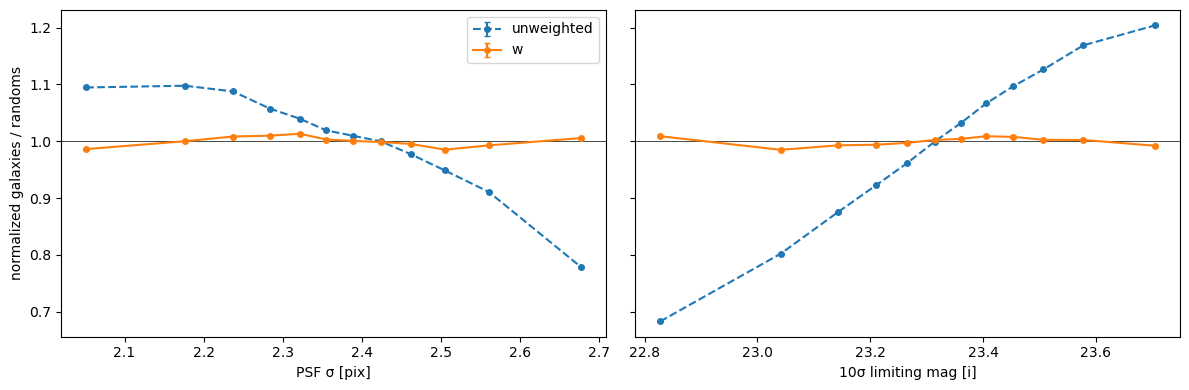

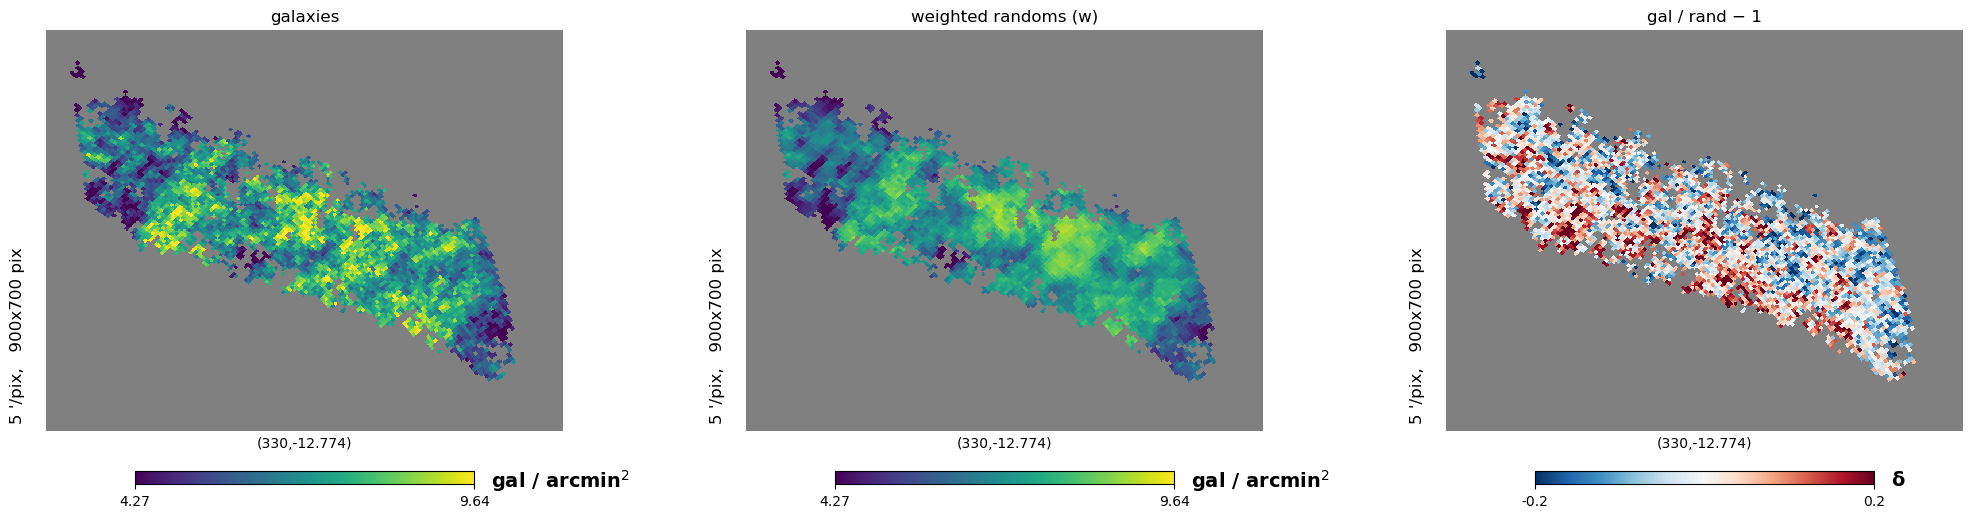

{'dens_gal': array([-1.6375e+30, -1.6375e+30, -1.6375e+30, ..., -1.6375e+30,
        -1.6375e+30, -1.6375e+30], shape=(196608,)),
 'dens_rand': array([-1.6375e+30, -1.6375e+30, -1.6375e+30, ..., -1.6375e+30,
        -1.6375e+30, -1.6375e+30], shape=(196608,)),
 'delta': array([-1.6375e+30, -1.6375e+30, -1.6375e+30, ..., -1.6375e+30,
        -1.6375e+30, -1.6375e+30], shape=(196608,)),
 'ok': array([False, False, False, ..., False, False, False], shape=(196608,)),
 'nside': 128}

In [16]:
gal_randoms, info = make_gal_randoms(metas, footprint, tract_mask, rand_per_arcmin2=100)

# # with extra maps (built at nside 512 with column_map)
# gal_randoms, info = make_gal_randoms(metas, footprint, tract_mask,
#                                      sys_maps={"background": bkg_map})

plot_weight_check(gal_randoms, info)
plot_density_maps(gal_randoms, info, metas, wcol="w")

In [11]:
from scipy.optimize import minimize

def _design(l, b, l0, b0, ls, bs, deg):
    """Polynomial terms in centred/scaled (l, b) up to total degree `deg`."""
    x, y = (l - l0) / ls, (b - b0) / bs
    return np.column_stack([x**i * y**j for i in range(deg + 1)
                            for j in range(deg + 1 - i)])

def smooth_star_weights(star_ra, star_dec, rand_ra, rand_dec, deg=2, nside_fit=32):
    """
    Fit log n_star(l, b) as a degree-`deg` polynomial with a Poisson likelihood on
    nside_fit pixels (random counts = effective area). Returns weights (mean 1)
    for every random, evaluated at its own (l, b).
    """
    to_gal = hp.Rotator(coord=["C", "G"])
    ls_, bs_ = to_gal(star_ra, star_dec, lonlat=True)
    lr_, br_ = to_gal(rand_ra, rand_dec, lonlat=True)
    lr_ = np.asarray(lr_); ls_ = np.asarray(ls_)
    # unwrap l around the field centre so the polynomial is continuous
    l_c = np.degrees(np.angle(np.mean(np.exp(1j * np.radians(lr_)))))
    wrap = lambda l: (l - l_c + 180) % 360 - 180 + l_c
    ls_, lr_ = wrap(ls_), wrap(lr_)

    npix  = hp.nside2npix(nside_fit)
    spix  = hp.ang2pix(nside_fit, star_ra, star_dec, lonlat=True, nest=True)
    rpix  = hp.ang2pix(nside_fit, rand_ra, rand_dec, lonlat=True, nest=True)
    N     = np.bincount(spix, minlength=npix).astype(float)
    R     = np.bincount(rpix, minlength=npix).astype(float)
    p     = np.flatnonzero(R > 0)

    # pixel (l, b) = mean position of its randoms
    lp = np.bincount(rpix, weights=lr_, minlength=npix)[p] / R[p]
    bp = np.bincount(rpix, weights=br_, minlength=npix)[p] / R[p]
    l0, b0, lsc, bsc = lp.mean(), bp.mean(), lp.std(), bp.std()

    X   = _design(lp, bp, l0, b0, lsc, bsc, deg)
    off = np.log(R[p])                               # exposure
    Np  = N[p]

    def nll(th):
        eta = X @ th + off
        return np.sum(np.exp(eta) - Np * eta)
    def grad(th):
        return X.T @ (np.exp(X @ th + off) - Np)

    th0 = np.zeros(X.shape[1]); th0[0] = np.log(Np.sum() / R[p].sum())
    fit = minimize(nll, th0, jac=grad, method="BFGS")

    w = np.exp(_design(lr_, br_, l0, b0, lsc, bsc, deg) @ fit.x)
    return w / w.mean(), dict(theta=fit.x, l=lr_, b=br_, star_l=ls_, star_b=bs_, n_star=int(Np.sum()))

re_weights, star_fits = [], []
for min_s, max_s in mag_min_max:
    m = (monsters["g_mag"] > min_s) & (monsters["g_mag"] <= max_s)
    deg = 1 if m.sum() < 2000 else 2               # keep bright bins simple
    w, sf = smooth_star_weights(monsters["coord_ra"][m], monsters["coord_dec"][m], star_randoms['ra'].data, star_randoms['dec'].data, deg=deg)
    re_weights.append(w); star_fits.append(sf)
    print(f"g ∈ ({min_s}, {max_s}]: {sf['n_star']:,} stars, deg={deg}, "
          f"w ∈ [{w.min():.2f}, {w.max():.2f}]")

g ∈ (7.5, 9.5]: 507 stars, deg=1, w ∈ [0.89, 1.12]
g ∈ (9.5, 10.5]: 3,302 stars, deg=2, w ∈ [0.38, 1.60]
g ∈ (10.5, 11.5]: 9,497 stars, deg=2, w ∈ [0.64, 1.86]
g ∈ (11.5, 12.5]: 22,945 stars, deg=2, w ∈ [0.57, 1.99]
g ∈ (12.5, 13.5]: 51,946 stars, deg=2, w ∈ [0.54, 2.11]
g ∈ (13.5, 14.5]: 99,953 stars, deg=2, w ∈ [0.48, 2.33]
g ∈ (14.5, 15.5]: 181,654 stars, deg=2, w ∈ [0.44, 2.54]
g ∈ (15.5, 16.5]: 318,013 stars, deg=2, w ∈ [0.39, 2.81]
g ∈ (16.5, 20.5]: 4,291,407 stars, deg=2, w ∈ [0.32, 3.41]


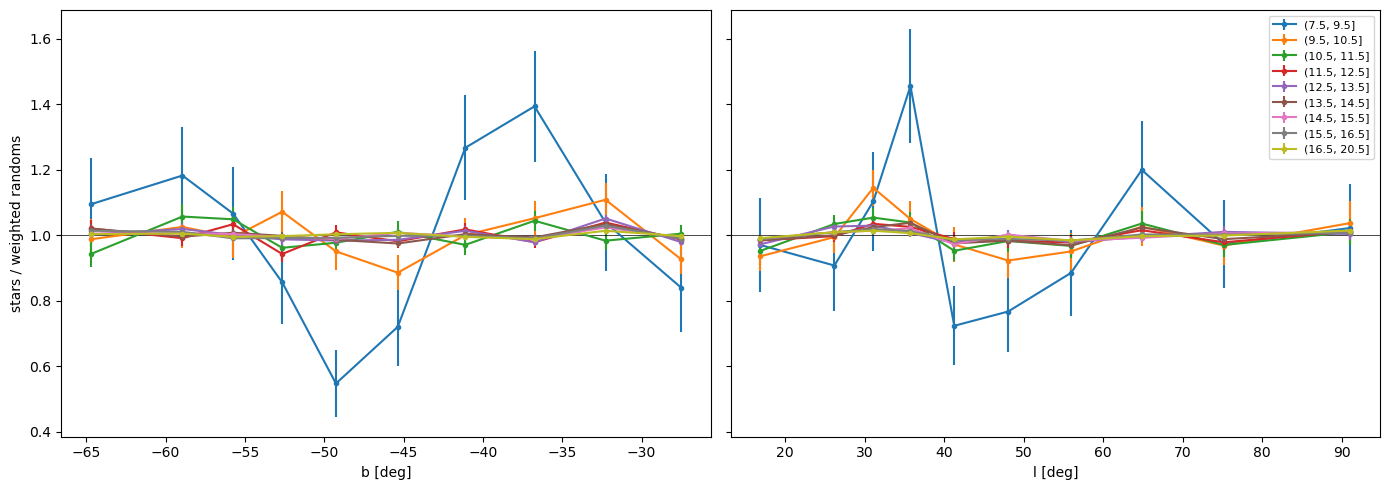

In [12]:
def ratio_1d(xs, xr, wr, edges):
    hs, _ = np.histogram(xs, edges)
    hr, _ = np.histogram(xr, edges, weights=wr)
    r = hs / hr * wr.sum() / len(xs)
    return 0.5 * (edges[1:] + edges[:-1]), r, np.sqrt(hs) / hr * wr.sum() / len(xs)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for (min_s, max_s), w, sf in zip(mag_min_max, re_weights, star_fits):
    for a, key, skey in [(ax[0], "b", "star_b"), (ax[1], "l", "star_l")]:
        edges = np.quantile(sf[key], np.linspace(0, 1, 11))
        x, r, e = ratio_1d(sf[skey], sf[key], w, edges)
        a.errorbar(x, r, e, fmt="o-", ms=3, label=f"({min_s}, {max_s}]")
for a, lab in zip(ax, ["b [deg]", "l [deg]"]):
    a.axhline(1, c="k", lw=0.5); a.set_xlabel(lab)
ax[0].set_ylabel("stars / weighted randoms"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

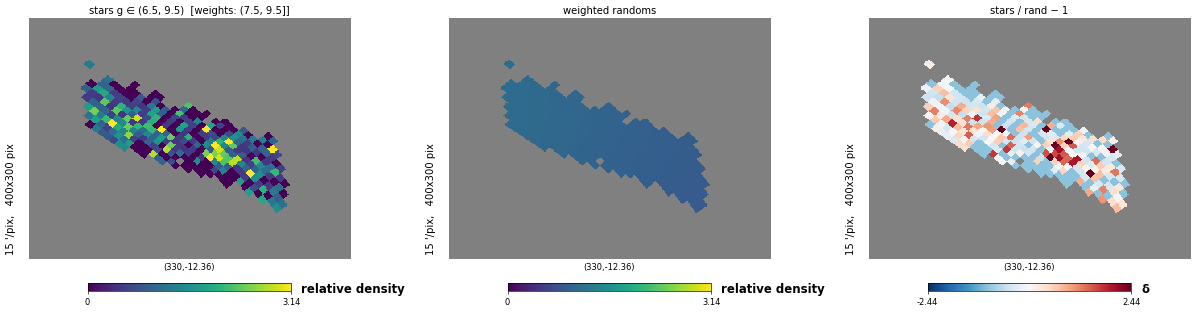

g ∈ (6.5, 9.5)  [weights: (7.5, 9.5]]: 493 stars, 303 pixels, δ rms = 0.926 (Poisson ≈ 0.814)


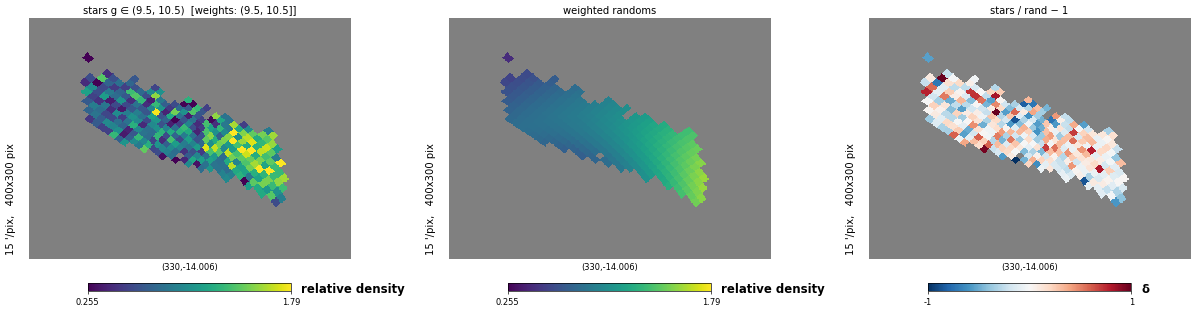

g ∈ (9.5, 10.5)  [weights: (9.5, 10.5]]: 3,153 stars, 303 pixels, δ rms = 0.342 (Poisson ≈ 0.334)


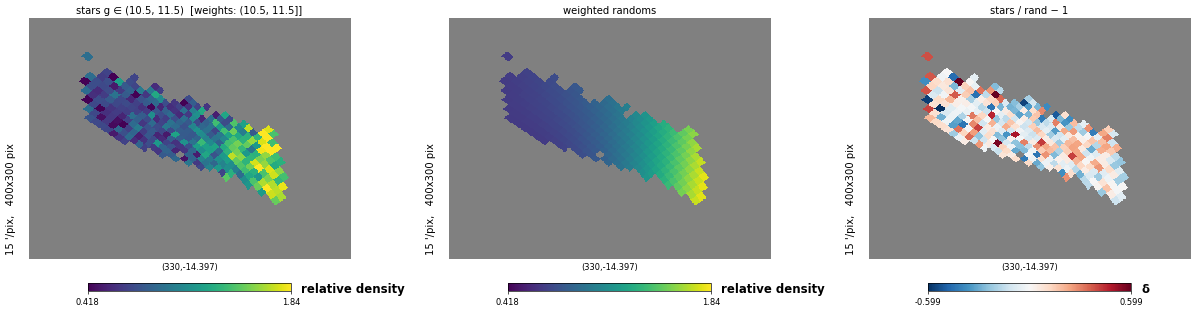

g ∈ (10.5, 11.5)  [weights: (10.5, 11.5]]: 8,996 stars, 303 pixels, δ rms = 0.213 (Poisson ≈ 0.200)


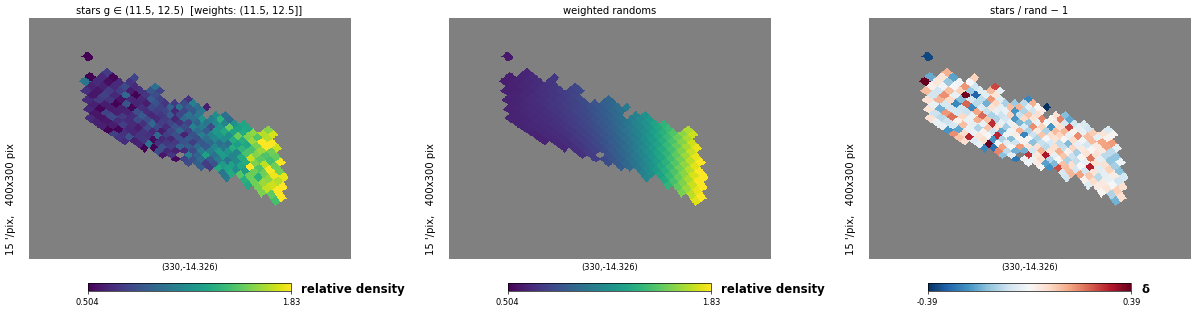

g ∈ (11.5, 12.5)  [weights: (11.5, 12.5]]: 21,738 stars, 303 pixels, δ rms = 0.135 (Poisson ≈ 0.130)


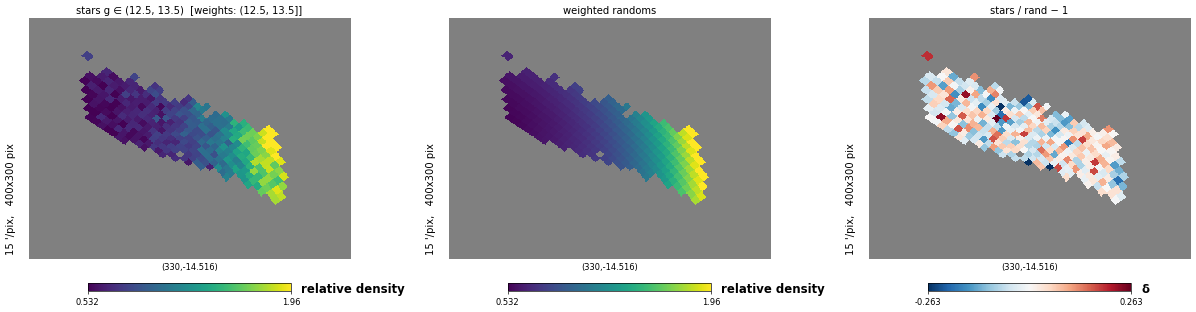

g ∈ (12.5, 13.5)  [weights: (12.5, 13.5]]: 48,963 stars, 303 pixels, δ rms = 0.090 (Poisson ≈ 0.088)


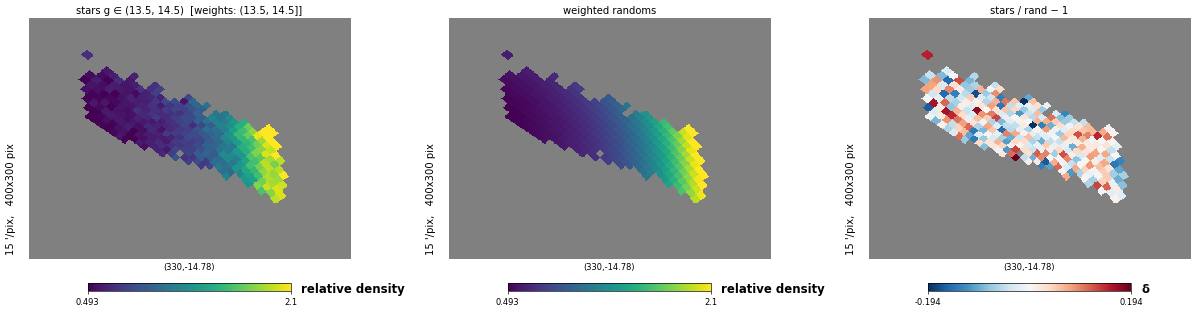

g ∈ (13.5, 14.5)  [weights: (13.5, 14.5]]: 94,257 stars, 303 pixels, δ rms = 0.074 (Poisson ≈ 0.065)


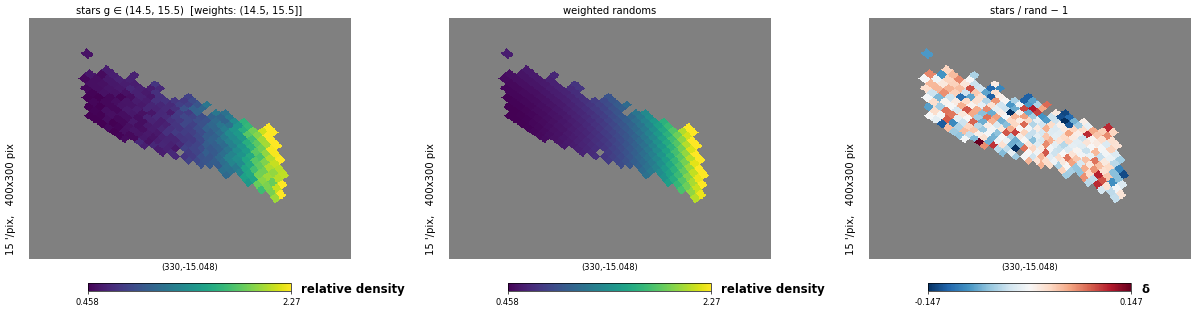

g ∈ (14.5, 15.5)  [weights: (14.5, 15.5]]: 171,129 stars, 303 pixels, δ rms = 0.056 (Poisson ≈ 0.049)


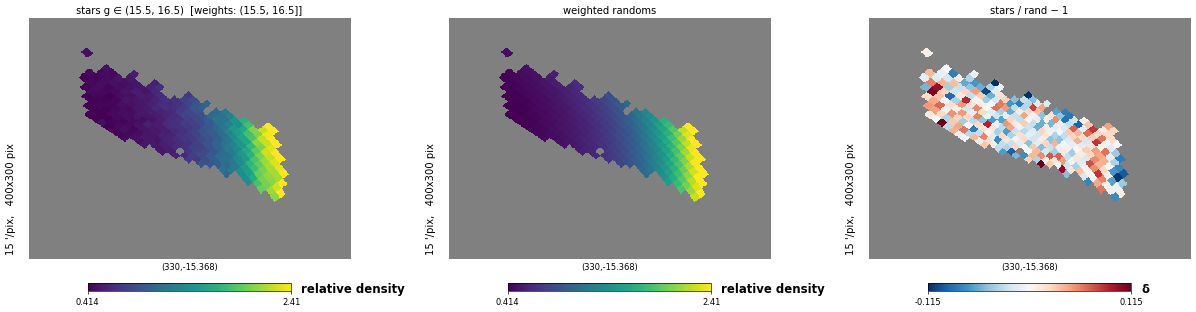

g ∈ (15.5, 16.5)  [weights: (15.5, 16.5]]: 299,235 stars, 303 pixels, δ rms = 0.045 (Poisson ≈ 0.038)


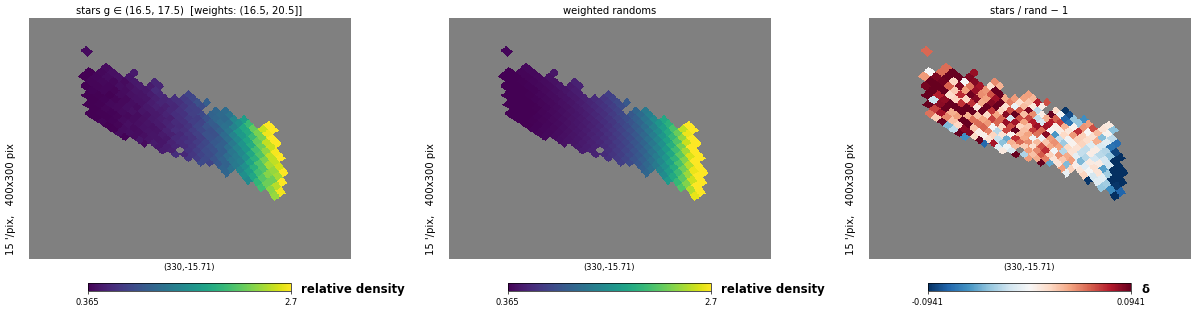

g ∈ (16.5, 17.5)  [weights: (16.5, 20.5]]: 497,405 stars, 303 pixels, δ rms = 0.054 (Poisson ≈ 0.031)


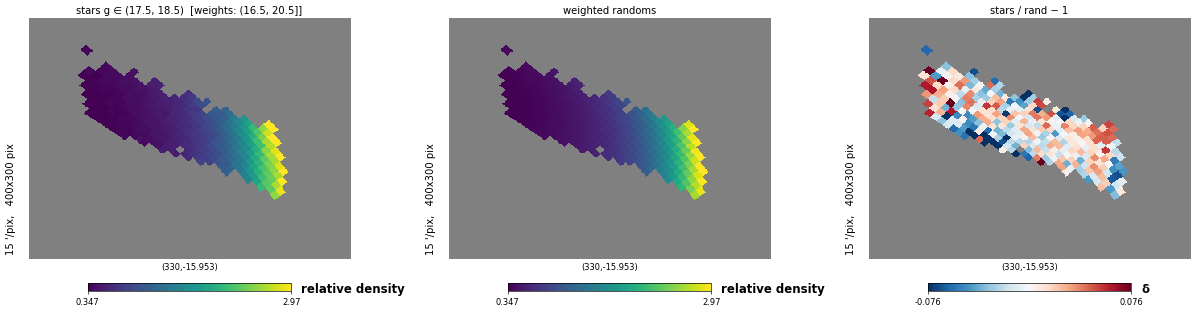

g ∈ (17.5, 18.5)  [weights: (16.5, 20.5]]: 761,802 stars, 303 pixels, δ rms = 0.036 (Poisson ≈ 0.025)


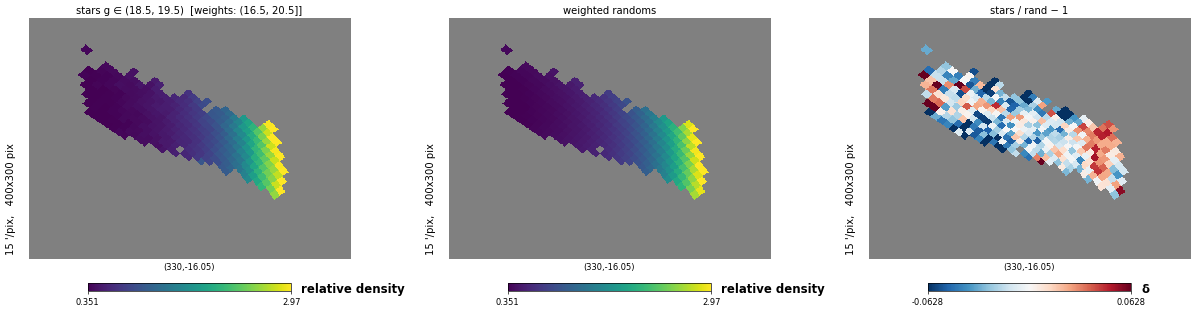

g ∈ (18.5, 19.5)  [weights: (16.5, 20.5]]: 1,118,134 stars, 303 pixels, δ rms = 0.038 (Poisson ≈ 0.021)


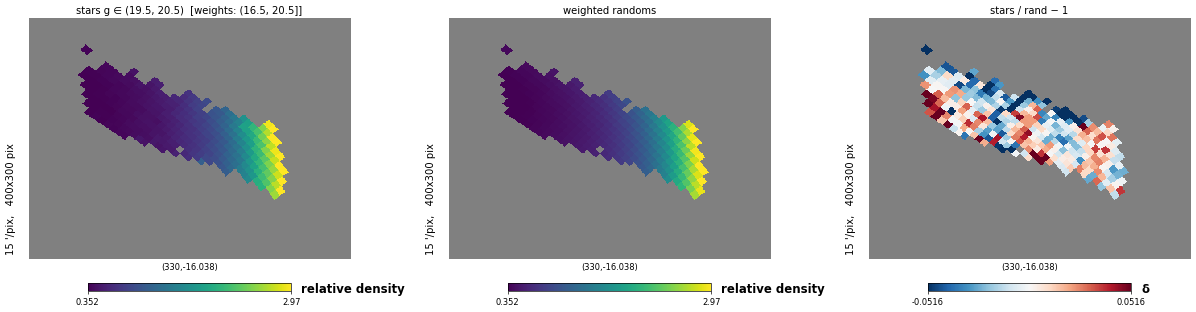

g ∈ (19.5, 20.5)  [weights: (16.5, 20.5]]: 1,656,436 stars, 303 pixels, δ rms = 0.040 (Poisson ≈ 0.017)


In [13]:
def plot_star_maps(star_ra, star_dec, rand_ra, rand_dec, w, title="",
                   nside_plot=32, min_frac=0.5, rand_pix=None,
                   rot_ra=330, reso=15.0, xsize=400, ysize=300, delta_lim=None):
    npix = hp.nside2npix(nside_plot)
    spix = hp.ang2pix(nside_plot, star_ra, star_dec, lonlat=True, nest=True)
    if rand_pix is None:
        rand_pix = hp.ang2pix(nside_plot, rand_ra, rand_dec, lonlat=True, nest=True)

    N  = np.bincount(spix,     minlength=npix).astype(float)
    Ru = np.bincount(rand_pix, minlength=npix).astype(float)            # area
    Rw = np.bincount(rand_pix, weights=w, minlength=npix)                 # model

    ok = Ru > min_frac * np.median(Ru[Ru > 0])         # drop mostly-empty edge pixels
    Rw_s = Rw * N[ok].sum() / Rw[ok].sum()             # expected star counts per pixel
    area = Ru / Ru[ok].mean()                          # relative area

    rel_s = np.full(npix, hp.UNSEEN); rel_s[ok] = N[ok]    / area[ok] / (N[ok].sum()    / area[ok].sum())
    rel_r = np.full(npix, hp.UNSEEN); rel_r[ok] = Rw_s[ok] / area[ok] / (Rw_s[ok].sum() / area[ok].sum())
    delta = np.full(npix, hp.UNSEEN); delta[ok] = N[ok] / Rw_s[ok] - 1

    # color ranges
    vmin, vmax = np.percentile(rel_s[ok], [2, 98])
    pois = np.sqrt(np.mean(1 / Rw_s[ok]))              # expected shot-noise rms of delta
    if delta_lim is None:
        delta_lim = max(3 * pois, 0.05)

    rot  = (rot_ra, np.median(star_dec))
    fig  = plt.figure(figsize=(21, 5), dpi=60)
    base = dict(nest=True, rot=rot, reso=reso, xsize=xsize, ysize=ysize, fig=fig.number)
    dkw  = dict(base, min=vmin, max=vmax, unit="relative density")
    hp.gnomview(rel_s, sub=(1, 3, 1), title=f"stars {title}", **dkw)
    hp.gnomview(rel_r, sub=(1, 3, 2), title="weighted randoms", **dkw)
    hp.gnomview(delta, sub=(1, 3, 3), title="stars / rand − 1",
                min=-delta_lim, max=delta_lim, cmap="RdBu_r", unit="δ", **base)
    plt.show()

    print(f"{title}: {int(N[ok].sum()):,} stars, {ok.sum()} pixels, "
          f"δ rms = {delta[ok].std():.3f} (Poisson ≈ {pois:.3f})")
    return dict(rel_star=rel_s, rel_rand=rel_r, delta=delta, ok=ok)

nside_plot = 32
r_ra, r_dec = star_randoms["ra"].data, star_randoms["dec"].data
r_pix = hp.ang2pix(nside_plot, r_ra, r_dec, lonlat=True, nest=True)

for b, c, mag, dif in mag_cuts:
    m = (monsters["g_mag"] > mag - dif) & (monsters["g_mag"] < mag + dif)
    lo_w, hi_w = mag_min_max[c]
    plot_star_maps(np.asarray(monsters["coord_ra"][m]), np.asarray(monsters["coord_dec"][m]),
        r_ra, r_dec, re_weights[c],
        title=f"g ∈ ({mag - dif:g}, {mag + dif:g})  [weights: ({lo_w}, {hi_w}]]",
        nside_plot=nside_plot, rand_pix=r_pix)

In [14]:
def get_patch_centers(monst, npatch, path):
    """k-means patches from the lens monsters
    Saved to `path` so reruns use identical patches."""
    if os.path.exists(path):
        return np.load(path)
    cat = treecorr.Catalog(ra=monst["coord_ra"], dec=monst["coord_dec"],
                           ra_units="deg", dec_units="deg", npatch=npatch)
    np.save(path, cat.patch_centers)
    return cat.patch_centers

def build_gal_cats(meta, centers):
    kw  = dict(ra=meta["ra"], dec=meta["dec"], ra_units="deg", dec_units="deg",
               patch_centers=centers)
    wkw = dict(kw, w=meta["wsel"])                 # selection-weighted averages / counts
    r1 = meta["wsel"] * meta["fpfs1_de1_dg1"] + meta["dwsel_dg1"] * meta["fpfs1_e1"]
    r2 = meta["wsel"] * meta["fpfs1_de2_dg2"] + meta["dwsel_dg2"] * meta["fpfs1_e2"]
    return {
        # wsel already inside these two -> no catalog weight
        "ng":   treecorr.Catalog(g1=meta["fpfs1_e1"] * meta["wsel"],
                                 g2=meta["fpfs1_e2"] * meta["wsel"], **kw),
        "R":    treecorr.Catalog(k=0.5 * (r1 + r2), **kw),
        # galaxy properties and density: weighted by wsel
        "flux": treecorr.Catalog(k=meta["lsst_i_flux_gauss2"], **wkw),
        "size": treecorr.Catalog(k=1 + meta["fpfs1_m20"] / meta["fpfs1_m00"], **wkw),
        "snr":  treecorr.Catalog(k=meta["lsst_i_s2n_fpfs1"], **wkw),
        "nn":   treecorr.Catalog(**wkw),
    }

def lens_catalog(ra, dec, centers, w=None):
    return treecorr.Catalog(ra=ra, dec=dec, w=w, ra_units="deg", dec_units="deg",
                            patch_centers=centers)

def derived_vector(keys):
    """Function mapping the list of correlations -> concatenated data vector
    in QUANTITIES order. treecorr calls it once per jackknife realization."""
    def func(cl):
        c = dict(zip(keys, cl))
        R = c["R"].xi
        norm = lambda nn: nn.weight / nn.tot
        return np.concatenate([c["ng"].xi / R, c["ng"].xi_im / R, R,
                               c["flux"].xi, c["size"].xi, c["snr"].xi,
                               norm(c["nn"]), norm(c["nr"])])
    return func

def measure(lens_cat, gal_cats, gal_random, sep_min_as, sep_max_as, bin_size, out_path,
            extra_config=None, bin_type="Log"):
    """Run all correlations for one lens catalog and save everything."""
    cfg = dict(min_sep=sep_min_as / 60, max_sep=sep_max_as / 60, bin_size=bin_size,
               bin_type=bin_type, sep_units="arcmin",
               var_method="jackknife", cross_patch_weight="match")
    corrs = {"ng": treecorr.NGCorrelation(**cfg)}
    for k in ("R", "flux", "size", "snr"):
        corrs[k] = treecorr.NKCorrelation(**cfg)
    for k in ("nn",):
        corrs[k] = treecorr.NNCorrelation(**cfg)
    for k, c in corrs.items():
        c.process(lens_cat, gal_cats[k])
        print(f"  done {k}", flush=True)

    corrs['nr'] = treecorr.NNCorrelation(**cfg)
    corrs['nr'].process(lens_cat, gal_random)
    print('done nr')

    keys = list(corrs)
    clist = [corrs[k] for k in keys]
    func = derived_vector(keys)

    d = func(clist)
    A, w = treecorr.build_multi_cov_design_matrix(clist, "jackknife", func=func)
    Np = len(A)
    D = A - A.mean(0)
    cov = (Np - 1) / Np * D.T @ D             # identical to estimate_multi_cov

    nb = corrs["ng"].nbins
    out = dict(
        quantities=np.array(QUANTITIES),
        nbins=nb,
        r_as=np.asarray(corrs["ng"].meanr) * 60,
        edges_as=np.append(corrs["ng"].left_edges, corrs["ng"].right_edges[-1]) * 60,
        npairs=np.asarray(corrs["ng"].npairs),
        data=d,                                 # (7*nb,) concatenated
        cov=cov,                                # (7*nb, 7*nb) joint covariance
        design=A,                               # (npatch, 7*nb) jackknife rows
        design_w=w,
        patch_centers=lens_cat.patch_centers,
        n_lens=lens_cat.nobj,
        sumw_lens=lens_cat.sumw,
        config=dict(sep_min_as=sep_min_as, sep_max_as=sep_max_as,
                    bin_size=bin_size, bin_type=bin_type, **(extra_config or {})),
    )
    var = np.diag(cov)
    for i, q in enumerate(QUANTITIES):
        sl = slice(i * nb, (i + 1) * nb)
        out[q] = d[sl]
        out[q + "_var"] = var[sl]
    np.savez(out_path + ".npz", **{k: (np.array(v, dtype=object) if isinstance(v, dict) else v)
                                   for k, v in out.items()})
    return out

def make_rand_corr(rand_lens, gal_cats, gal_random, out_path,
                   sep_min, sep_max, bin_sep, bin_type="Log", extra_config=None):
    print(f"meas randoms -> {out_path}")
    return measure(rand_lens, gal_cats, gal_random, sep_min, sep_max, bin_sep, out_path,
                   bin_type=bin_type, extra_config=extra_config)

def make_star_corr(monster, star_mag, mag_dif, gal_cats, gal_random, centers, out_path,
                   sep_min, sep_max, bin_sep, bin_type="Log"):
    sel = (monster["g_mag"] > star_mag - mag_dif) & (monster["g_mag"] < star_mag + mag_dif)
    m = monster[sel]
    lens = lens_catalog(m["coord_ra"], m["coord_dec"], centers)
    print(f"meas star {star_mag}")
    return measure(lens, gal_cats, gal_random, sep_min, sep_max, bin_sep, out_path,
                   bin_type=bin_type,
                   extra_config=dict(star_mag=star_mag, frac_dif=mag_dif,
                                     mean_mag=float(np.mean(m["g_mag"]))))


In [17]:
metas_cut = metas[metas['lsst_i_s2n_fpfs1'] > 10]
centers    = get_patch_centers(monsters, NPATCH, f"{save_path}/patch_centers.npy")
gal_cats   = build_gal_cats(metas_cut, centers)
gal_random = lens_catalog(gal_randoms["ra"], gal_randoms["dec"], centers, w=gal_randoms['w'])
print("built gal")

rand_ra, rand_dec = star_randoms["ra"].data, star_randoms["dec"].data

# random lenses: one run per (separation binning, star-weight bin) pair
pairs = sorted({(b, c) for b, c, _, _ in mag_cuts})
for b, c in tqdm(pairs):
    rand_lens = lens_catalog(rand_ra, rand_dec, centers, w=re_weights[c])
    make_rand_corr(rand_lens, gal_cats, gal_random, f"{save_path}/rands_b{b}_w{c}",
                   *mag_bin_args[b],
                   extra_config=dict(bin_int=b, cut_int=c, mag_range=mag_min_max[c]))

# star lenses
for b, c, mag, dif in tqdm(mag_cuts):
    make_star_corr(monsters, mag, dif, gal_cats, gal_random, centers,
                   f"{save_path}/star_mag{mag}", *mag_bin_args[b])

built gal


  0%|          | 0/9 [00:00<?, ?it/s]

meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b0_w0
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b0_w1
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b0_w2
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b1_w3
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b1_w4
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint/rands_b1_w5
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> 

  0%|          | 0/12 [00:00<?, ?it/s]

meas star 8


...

  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr


/tmp/ipykernel_678185/222051272.py:40: RuntimeWarning: invalid value encountered in divide
  return np.concatenate([c["ng"].xi / R, c["ng"].xi_im / R, R,


meas star 10
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 11
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 12
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr


/tmp/ipykernel_678185/222051272.py:40: RuntimeWarning: divide by zero encountered in divide
  return np.concatenate([c["ng"].xi / R, c["ng"].xi_im / R, R,
/tmp/ipykernel_678185/222051272.py:71: RuntimeWarning: invalid value encountered in subtract
  D = A - A.mean(0)
/tmp/ipykernel_678185/222051272.py:72: RuntimeWarning: invalid value encountered in matmul
  cov = (Np - 1) / Np * D.T @ D             # identical to estimate_multi_cov


meas star 13
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 14
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 15
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 16
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 17
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 18
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 19
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas star 20
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr


## DEFINE RADIUS

mag 9.14, window radius 1189.1 arcsec (5946 pix), strongest tests: size (27.3), flux (18.4), dens (3.6), dens_cut: 135.1 arcsec (676 pix)


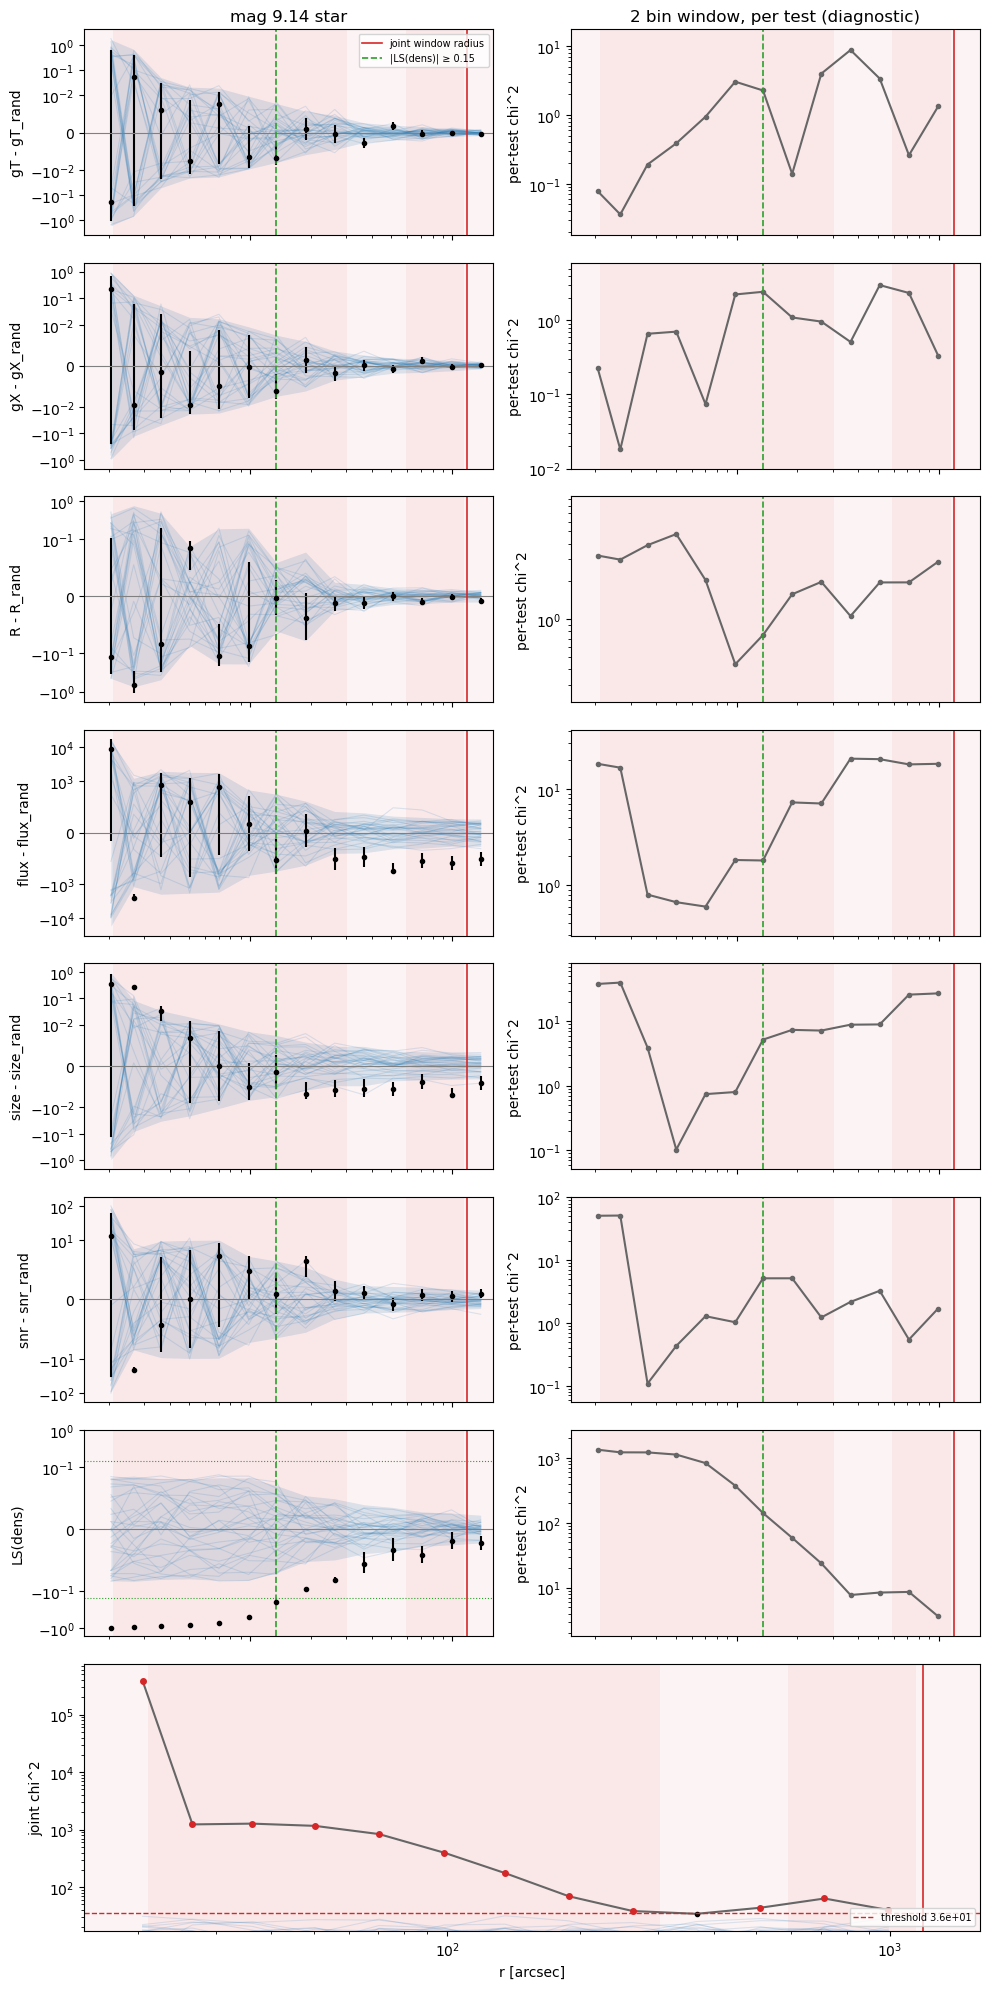

mag 10.11, window radius 225.2 arcsec (1126 pix), strongest tests: dens (28.8), size (4.0), flux (2.1), dens_cut: 70.4 arcsec (352 pix)


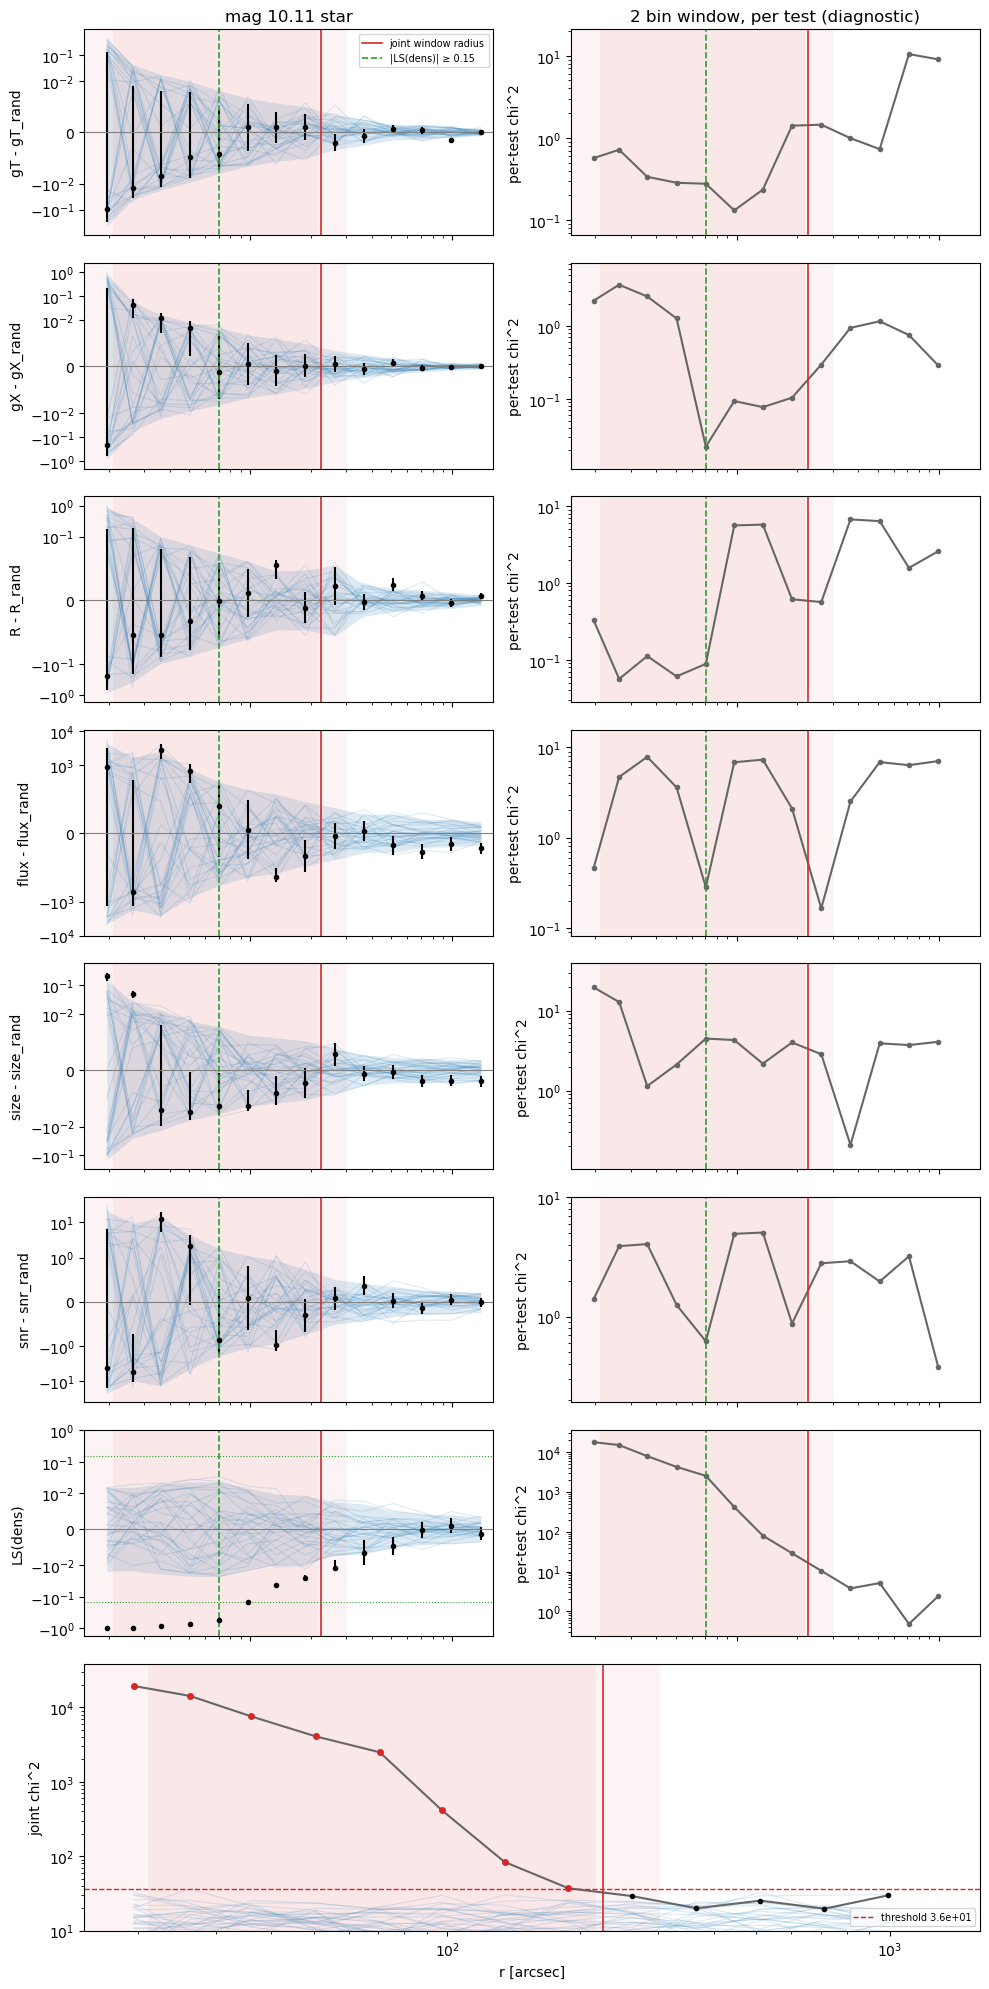

mag 11.08, window radius 161.4 arcsec (807 pix), strongest tests: dens (26.9), gX (5.4), size (4.4), dens_cut: 70.1 arcsec (350 pix)


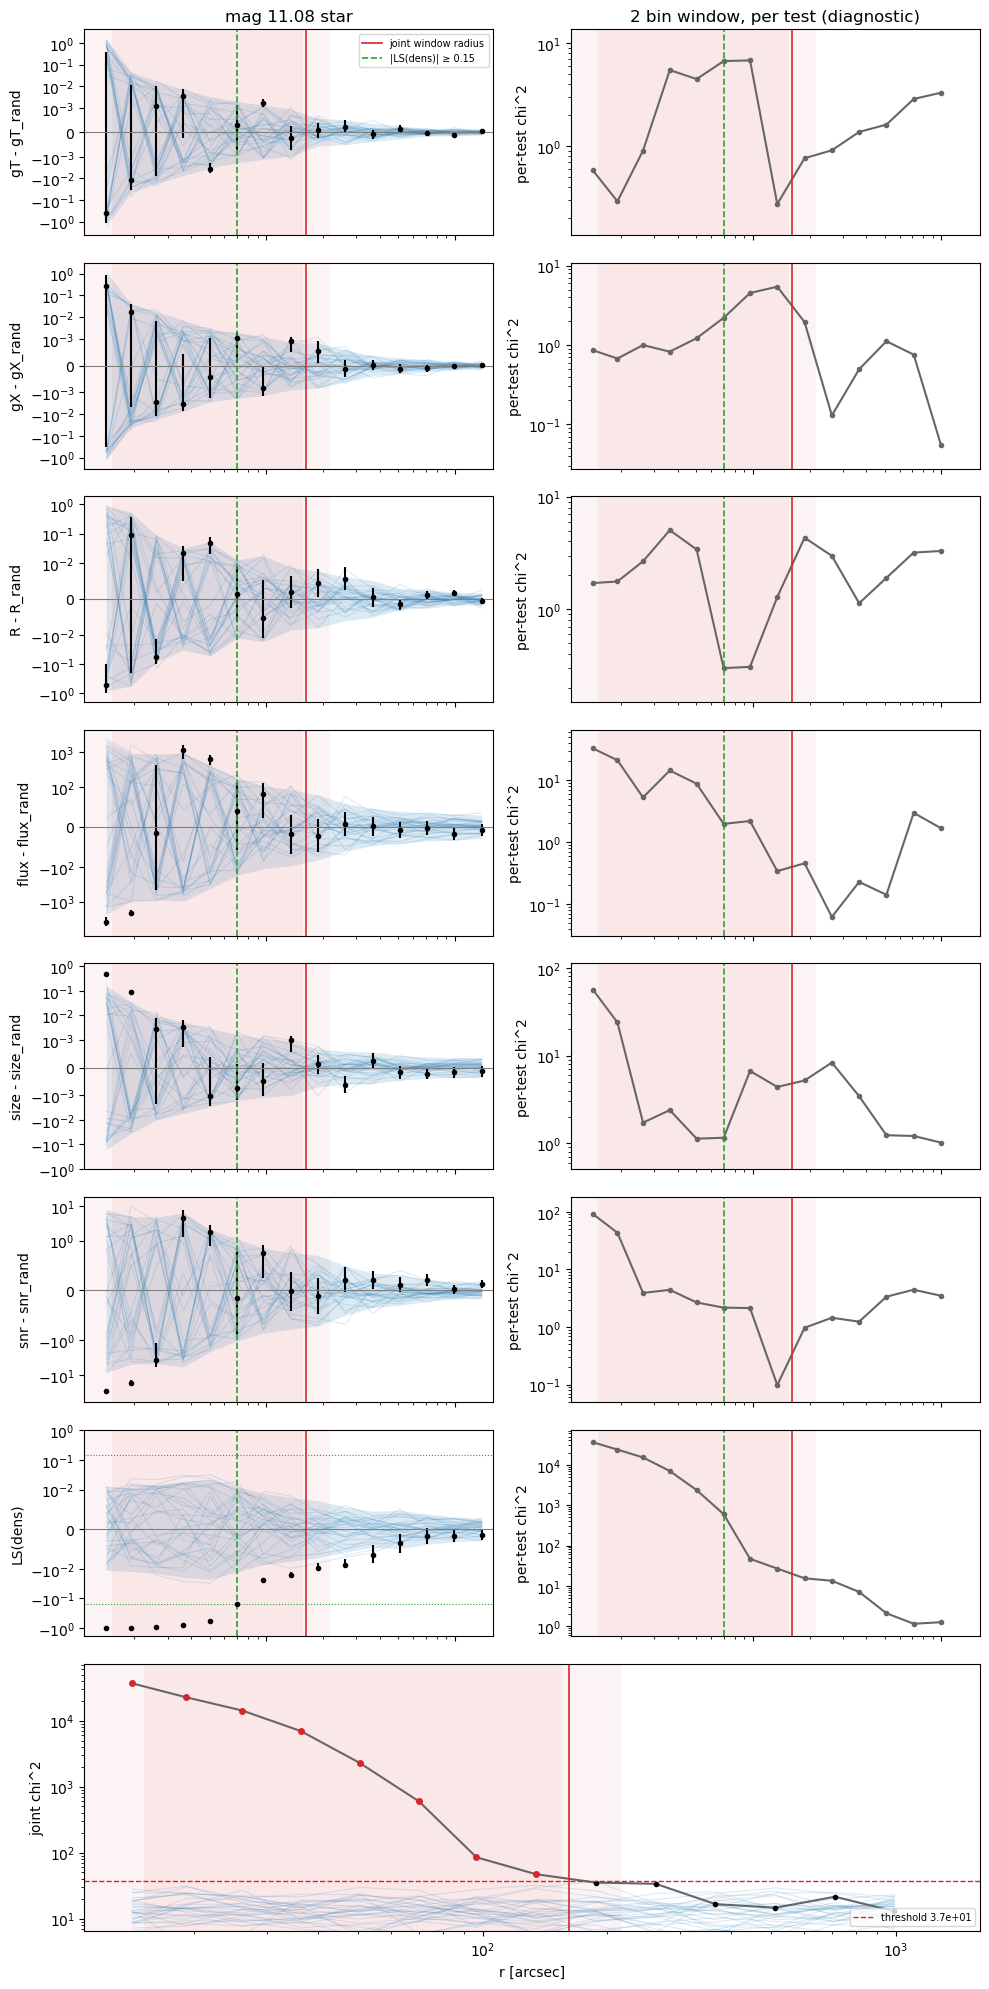

mag 12.08, window radius 58.3 arcsec (292 pix), strongest tests: dens (1094.3), size (5.4), gT (3.6), dens_cut: 49.3 arcsec (246 pix)


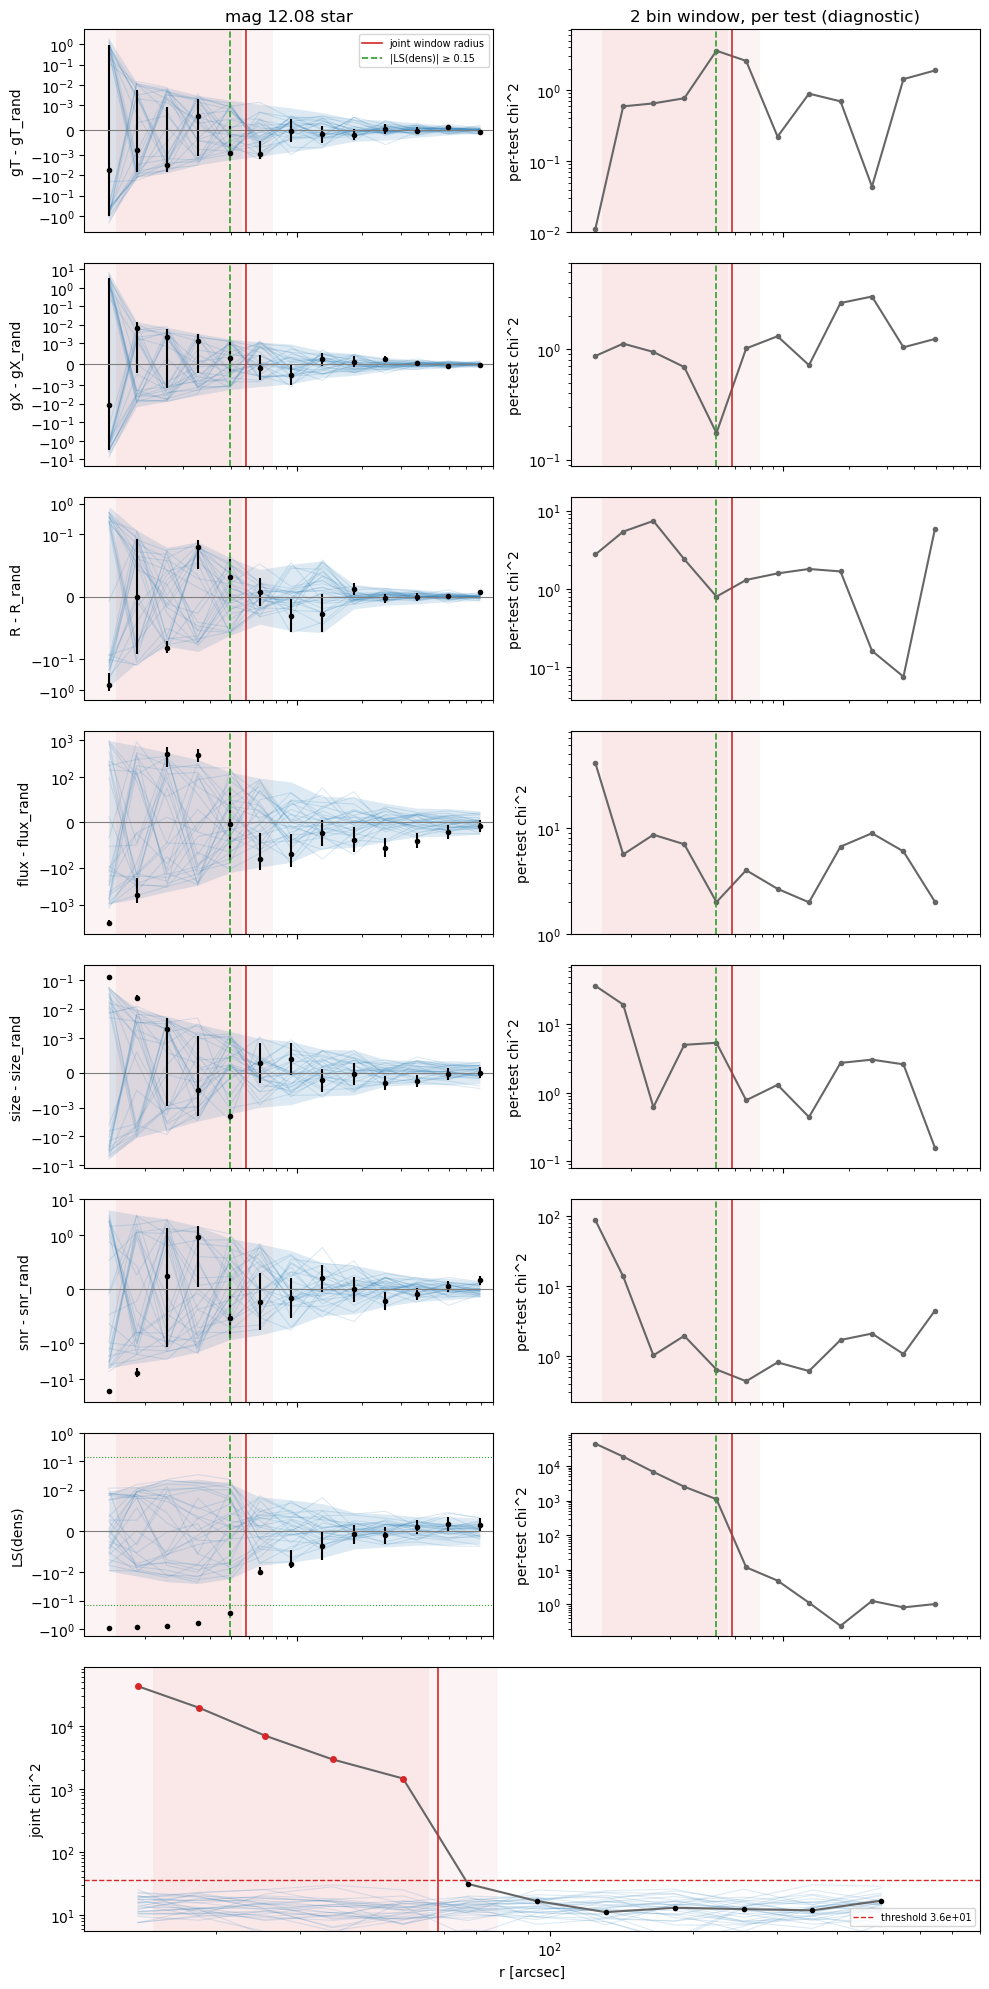

mag 13.06, window radius 57.9 arcsec (290 pix), strongest tests: dens (85.1), size (3.5), R (2.0), dens_cut: 35.4 arcsec (177 pix)


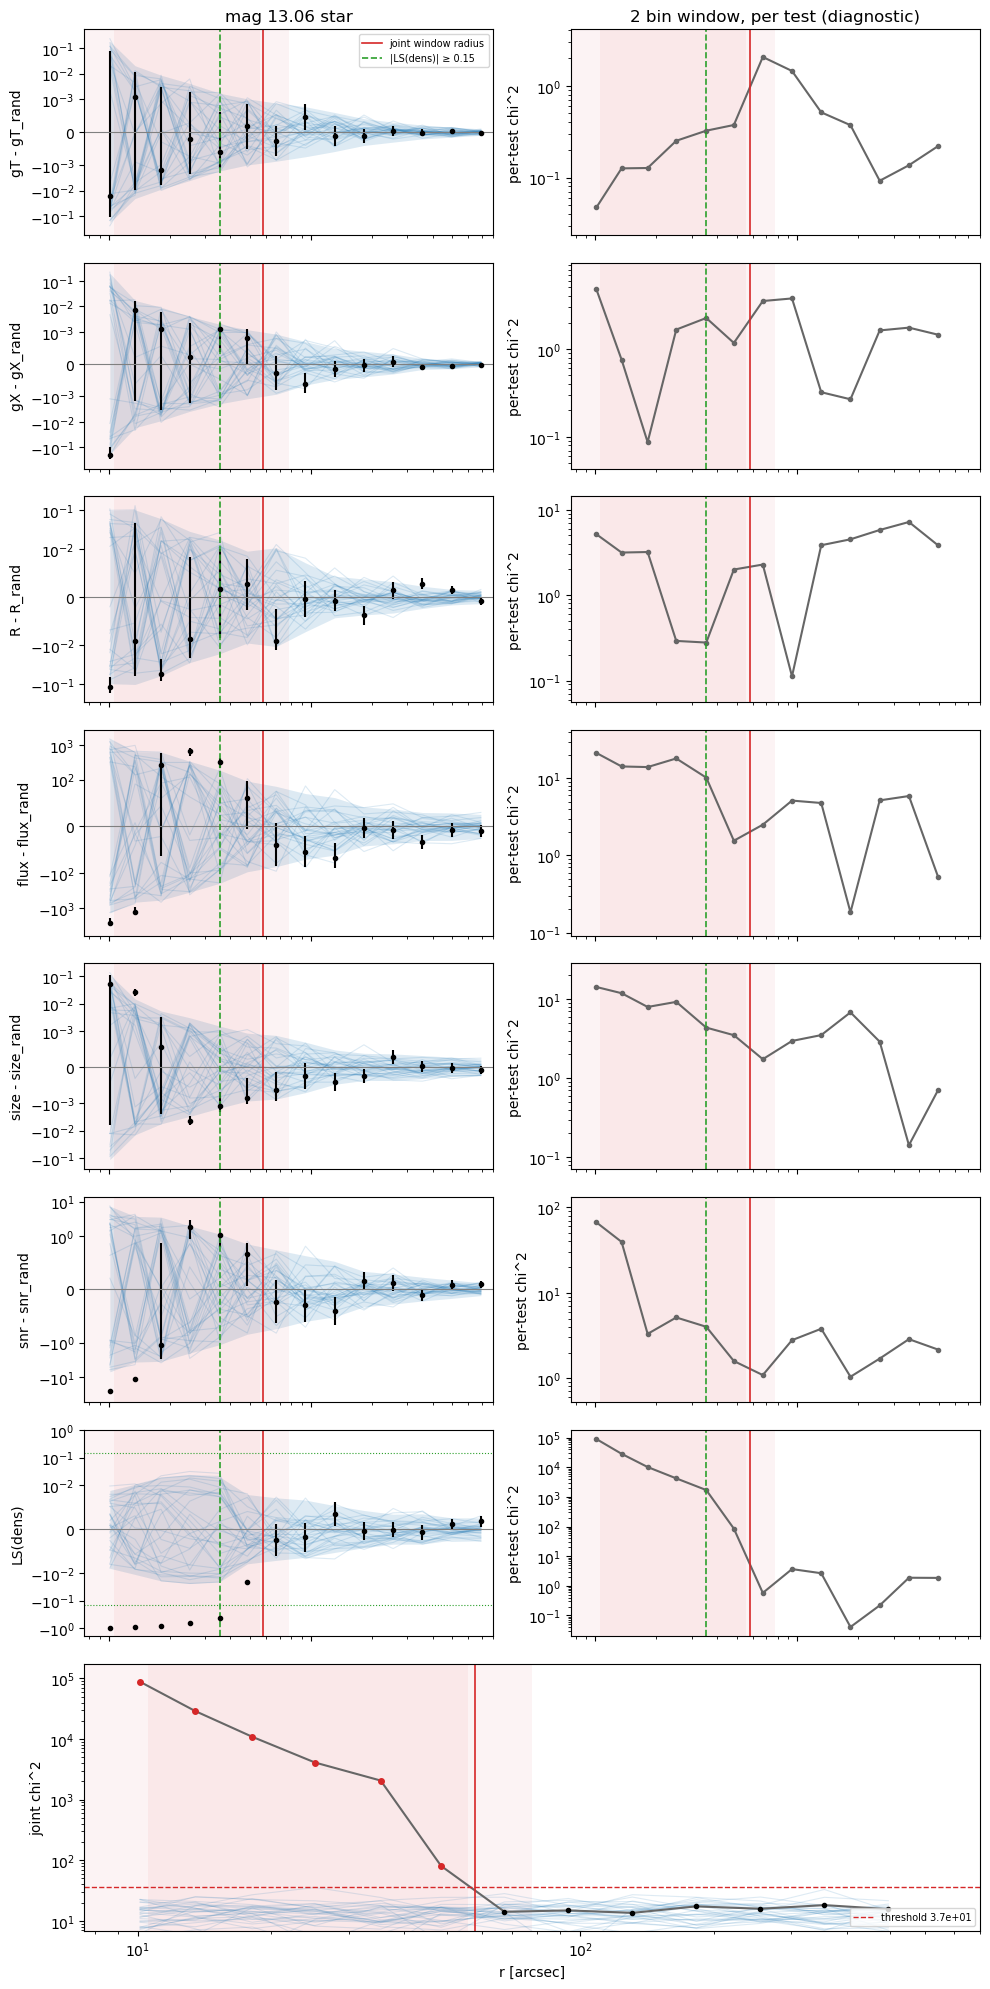

mag 14.05, window radius 41.6 arcsec (208 pix), strongest tests: dens (881.0), size (6.4), gT (5.0), dens_cut: 25.3 arcsec (126 pix)


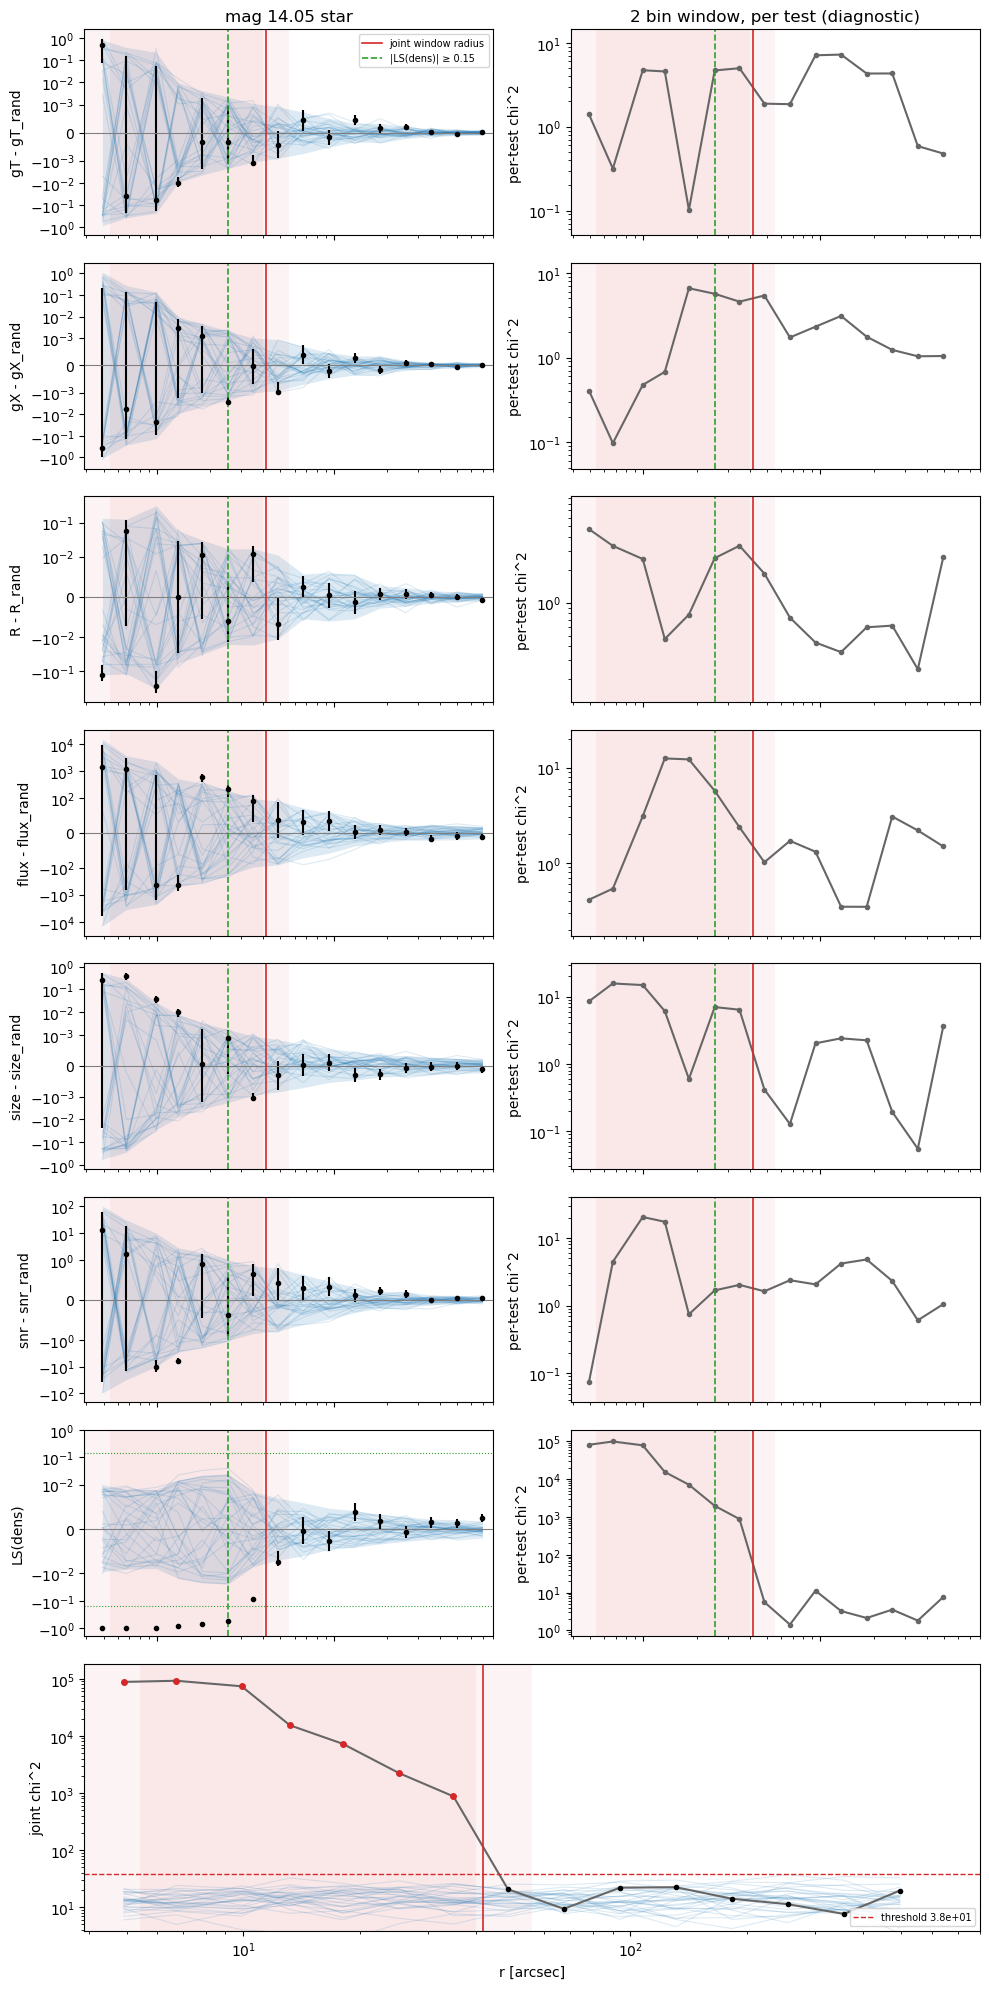

mag 15.05, window radius 213.1 arcsec (1066 pix), strongest tests: gX (15.6), size (14.2), dens (7.9), dens_cut: 24.6 arcsec (123 pix)


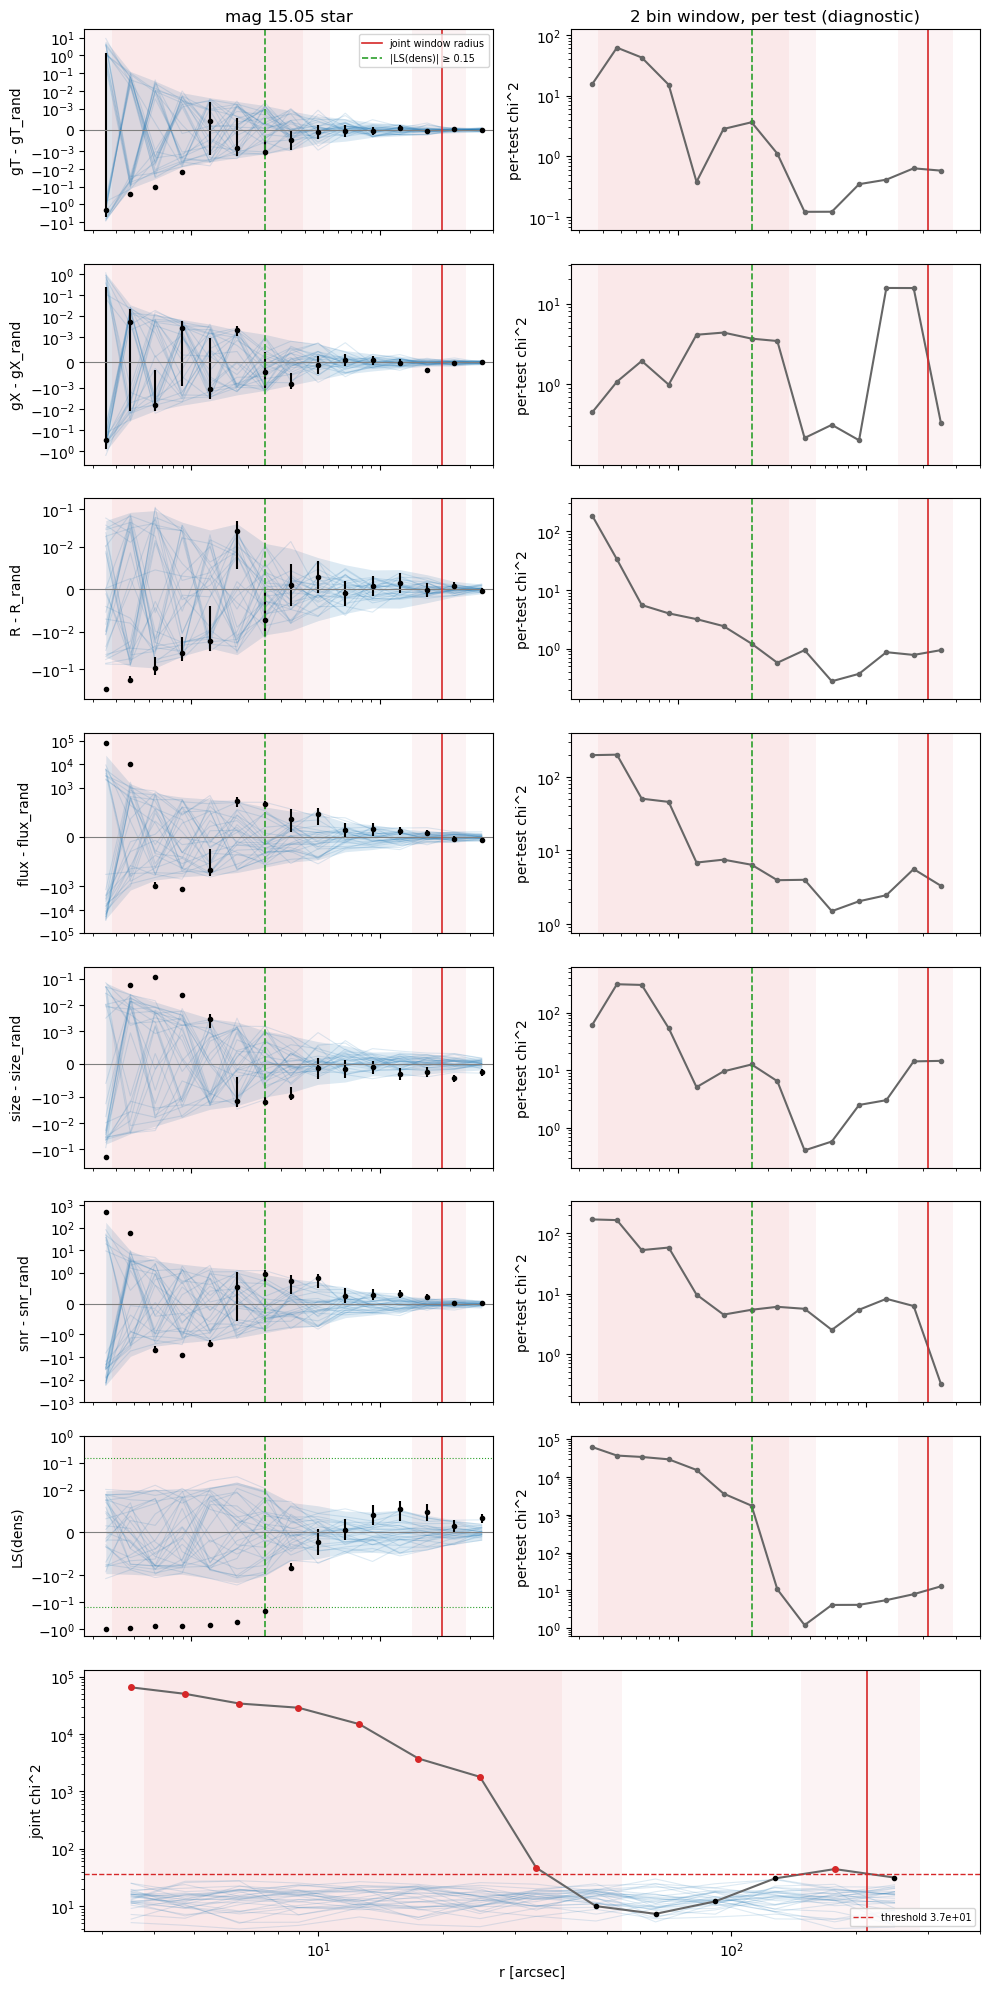

mag 16.05, window radius 40.4 arcsec (202 pix), strongest tests: dens (33.3), size (6.6), snr (4.7), dens_cut: 6.4 arcsec (32 pix)


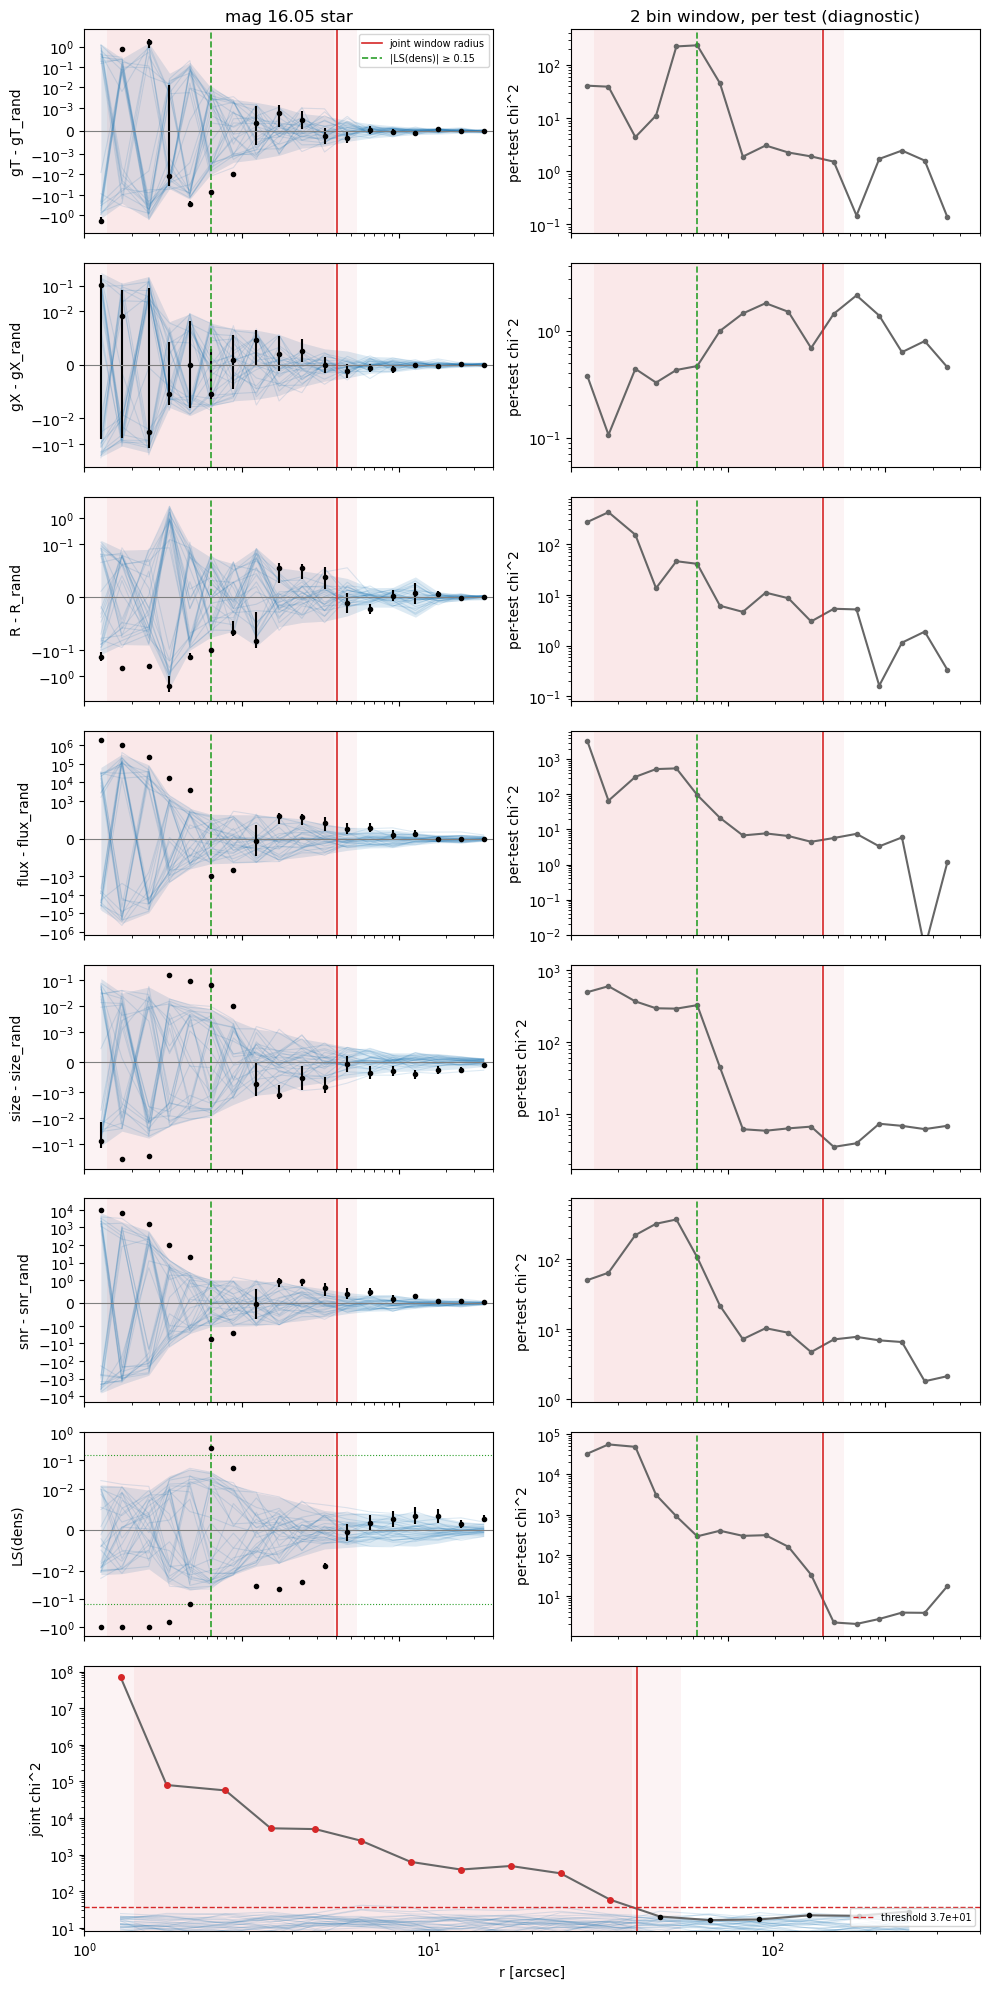

mag 17.04, window radius 297.3 arcsec (1487 pix), strongest tests: dens (29.3), size (28.6), R (16.4), dens_cut: 6.3 arcsec (32 pix)


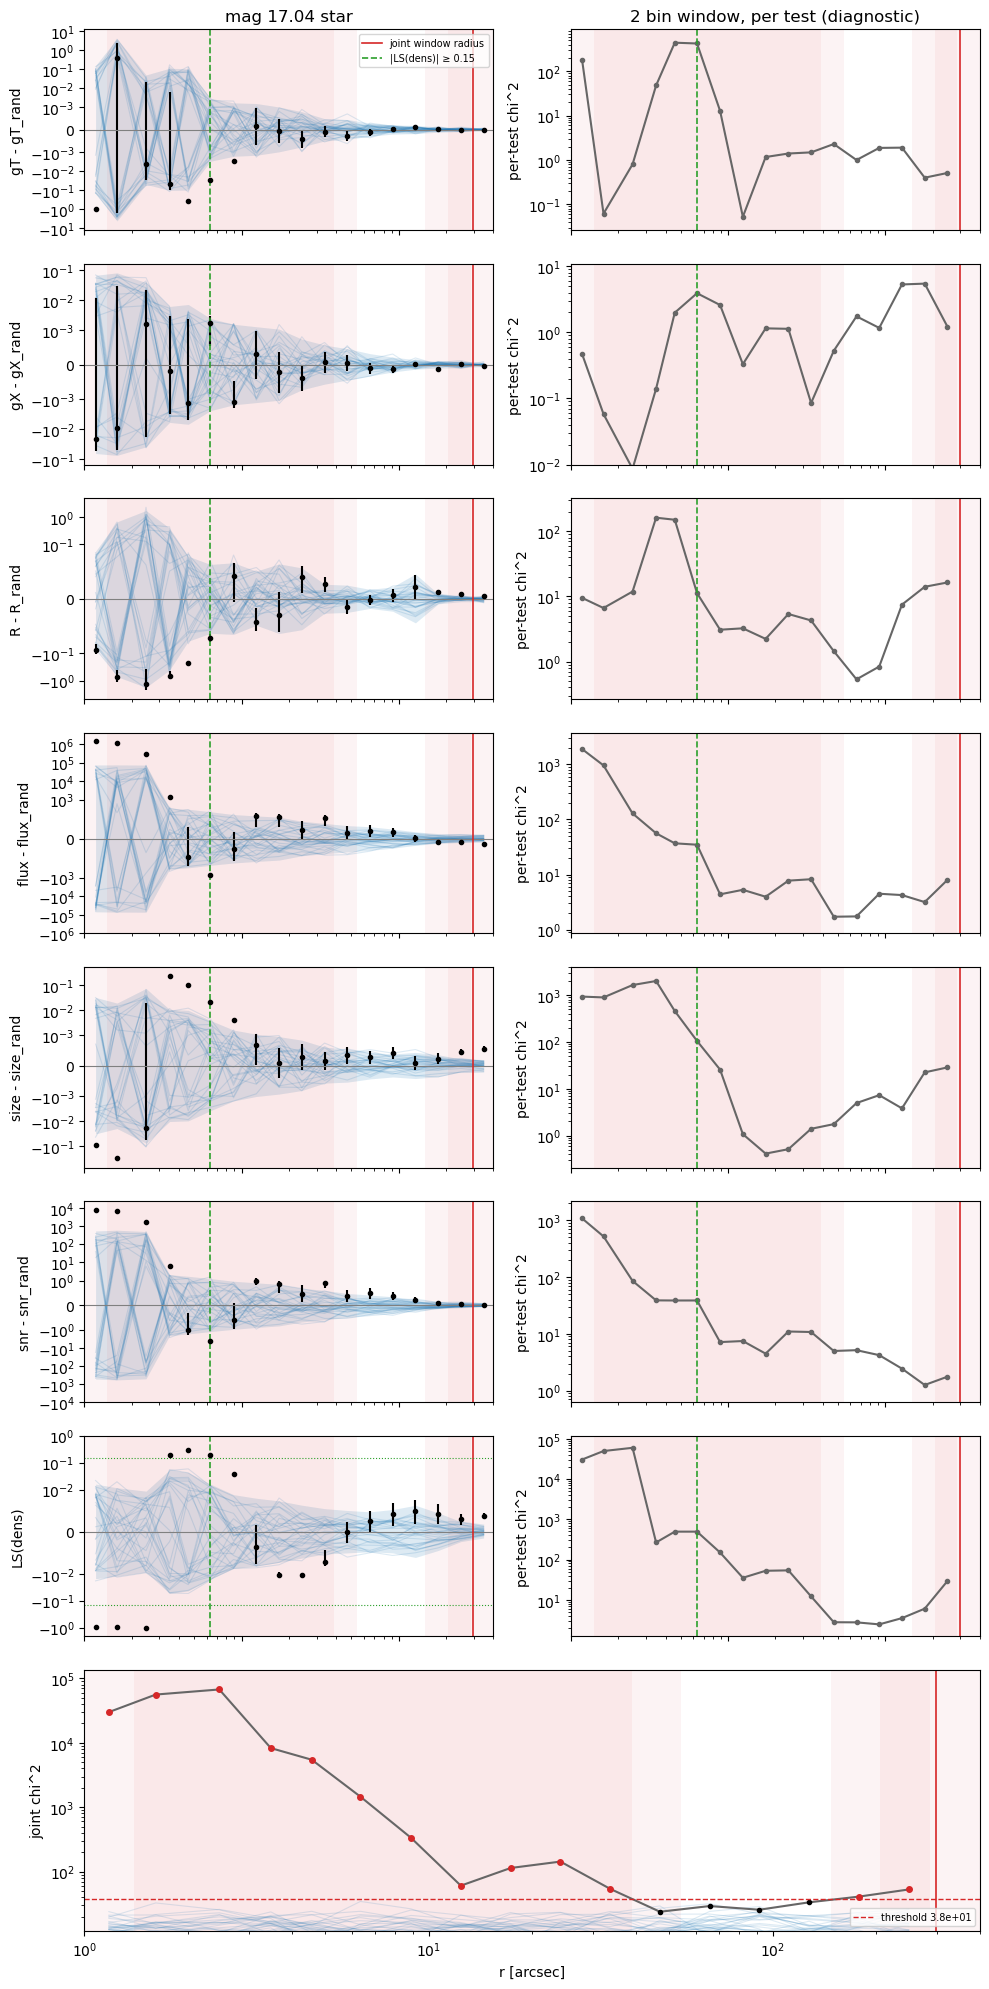

mag 18.03, window radius 297.3 arcsec (1487 pix), strongest tests: size (7.9), snr (4.6), R (2.8), dens_cut: 4.5 arcsec (23 pix)


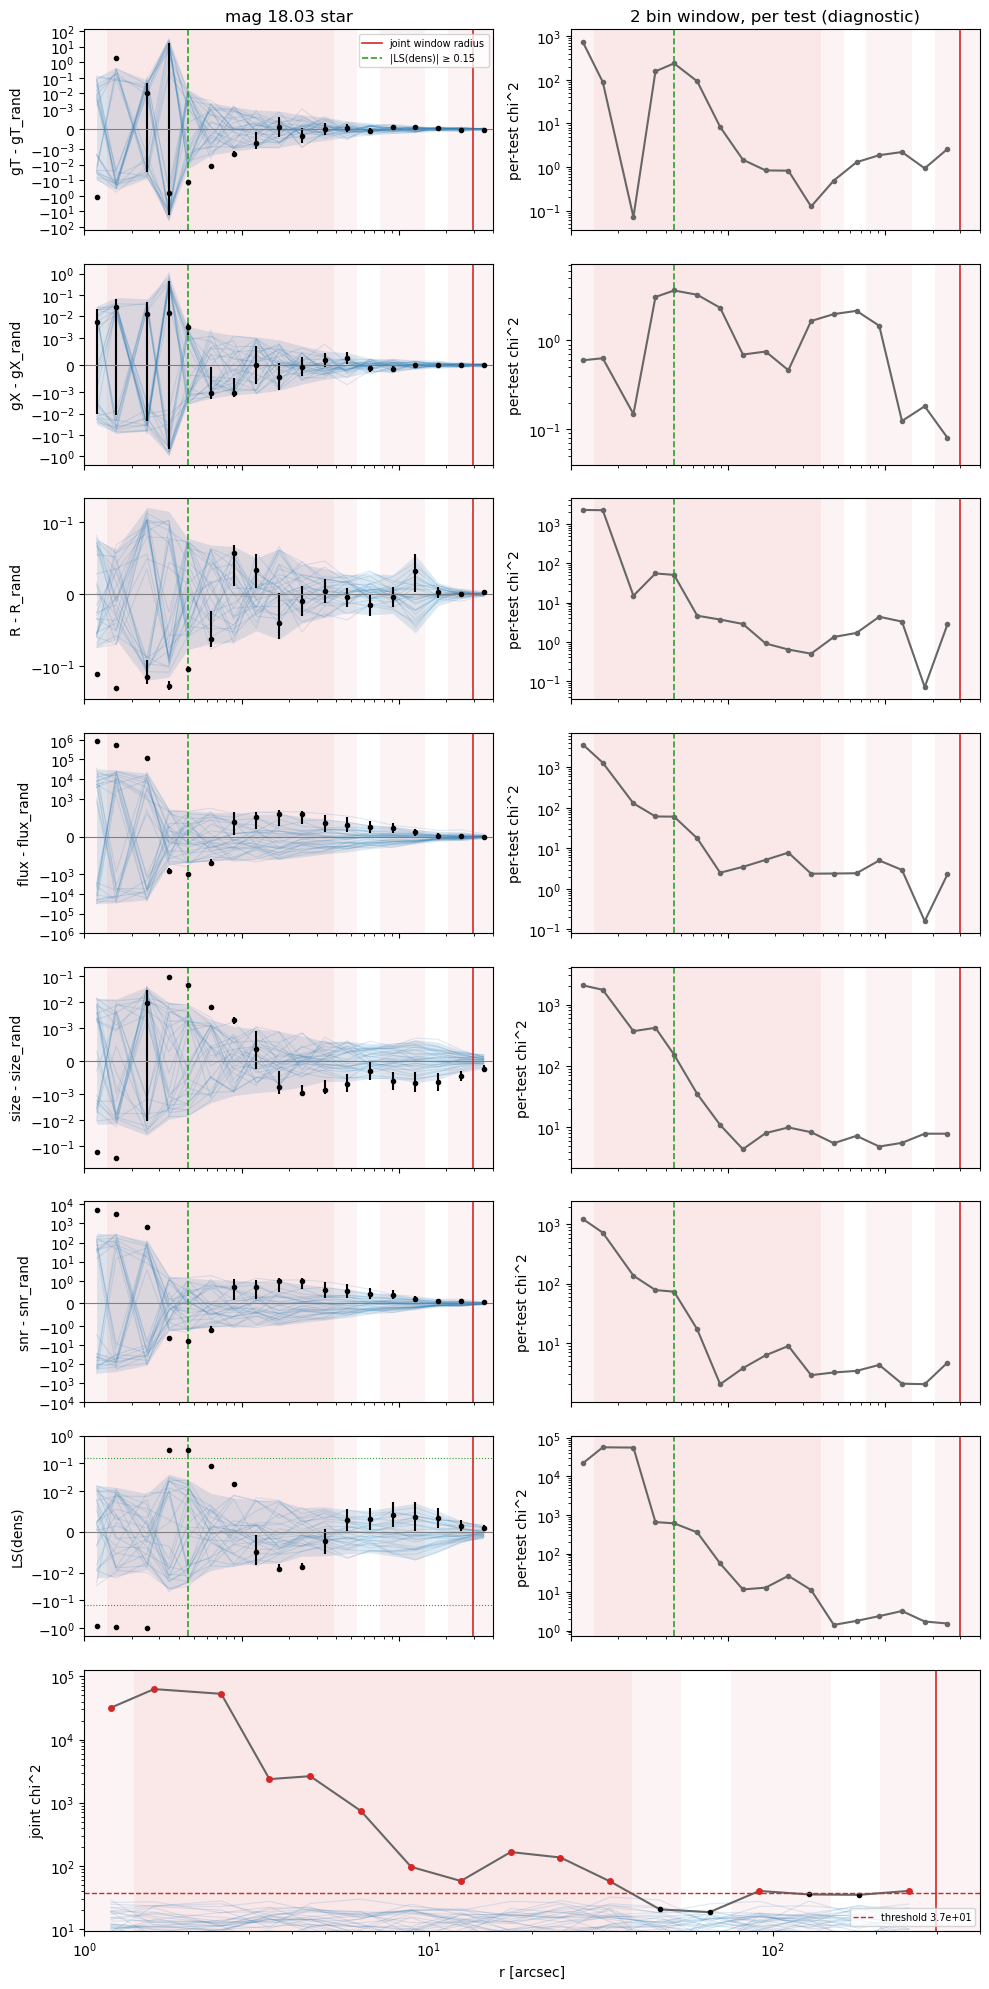

mag 19.03, window radius 297.3 arcsec (1487 pix), strongest tests: size (16.0), gT (4.2), gX (3.5), dens_cut: 4.5 arcsec (23 pix)


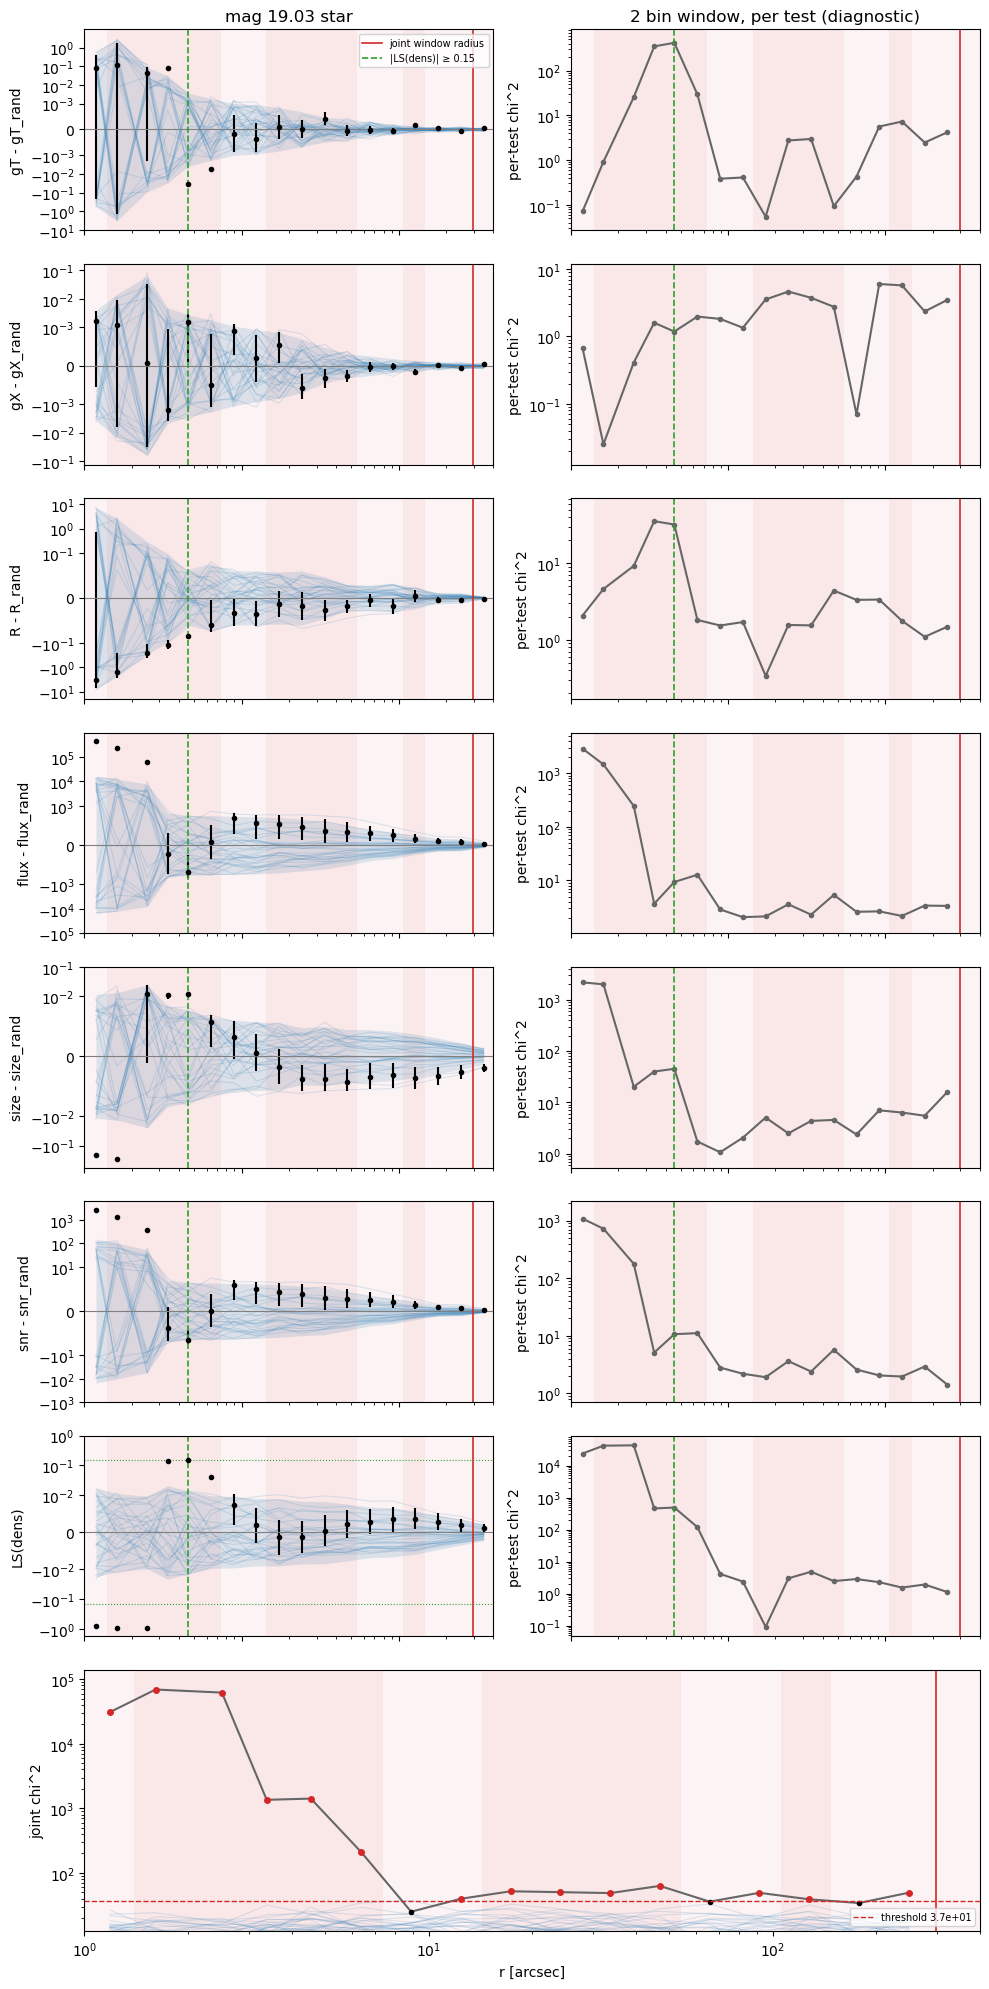

mag 20.03, window radius 28.9 arcsec (145 pix), strongest tests: snr (4.6), flux (3.9), gX (3.6), dens_cut: 2.5 arcsec (12 pix)


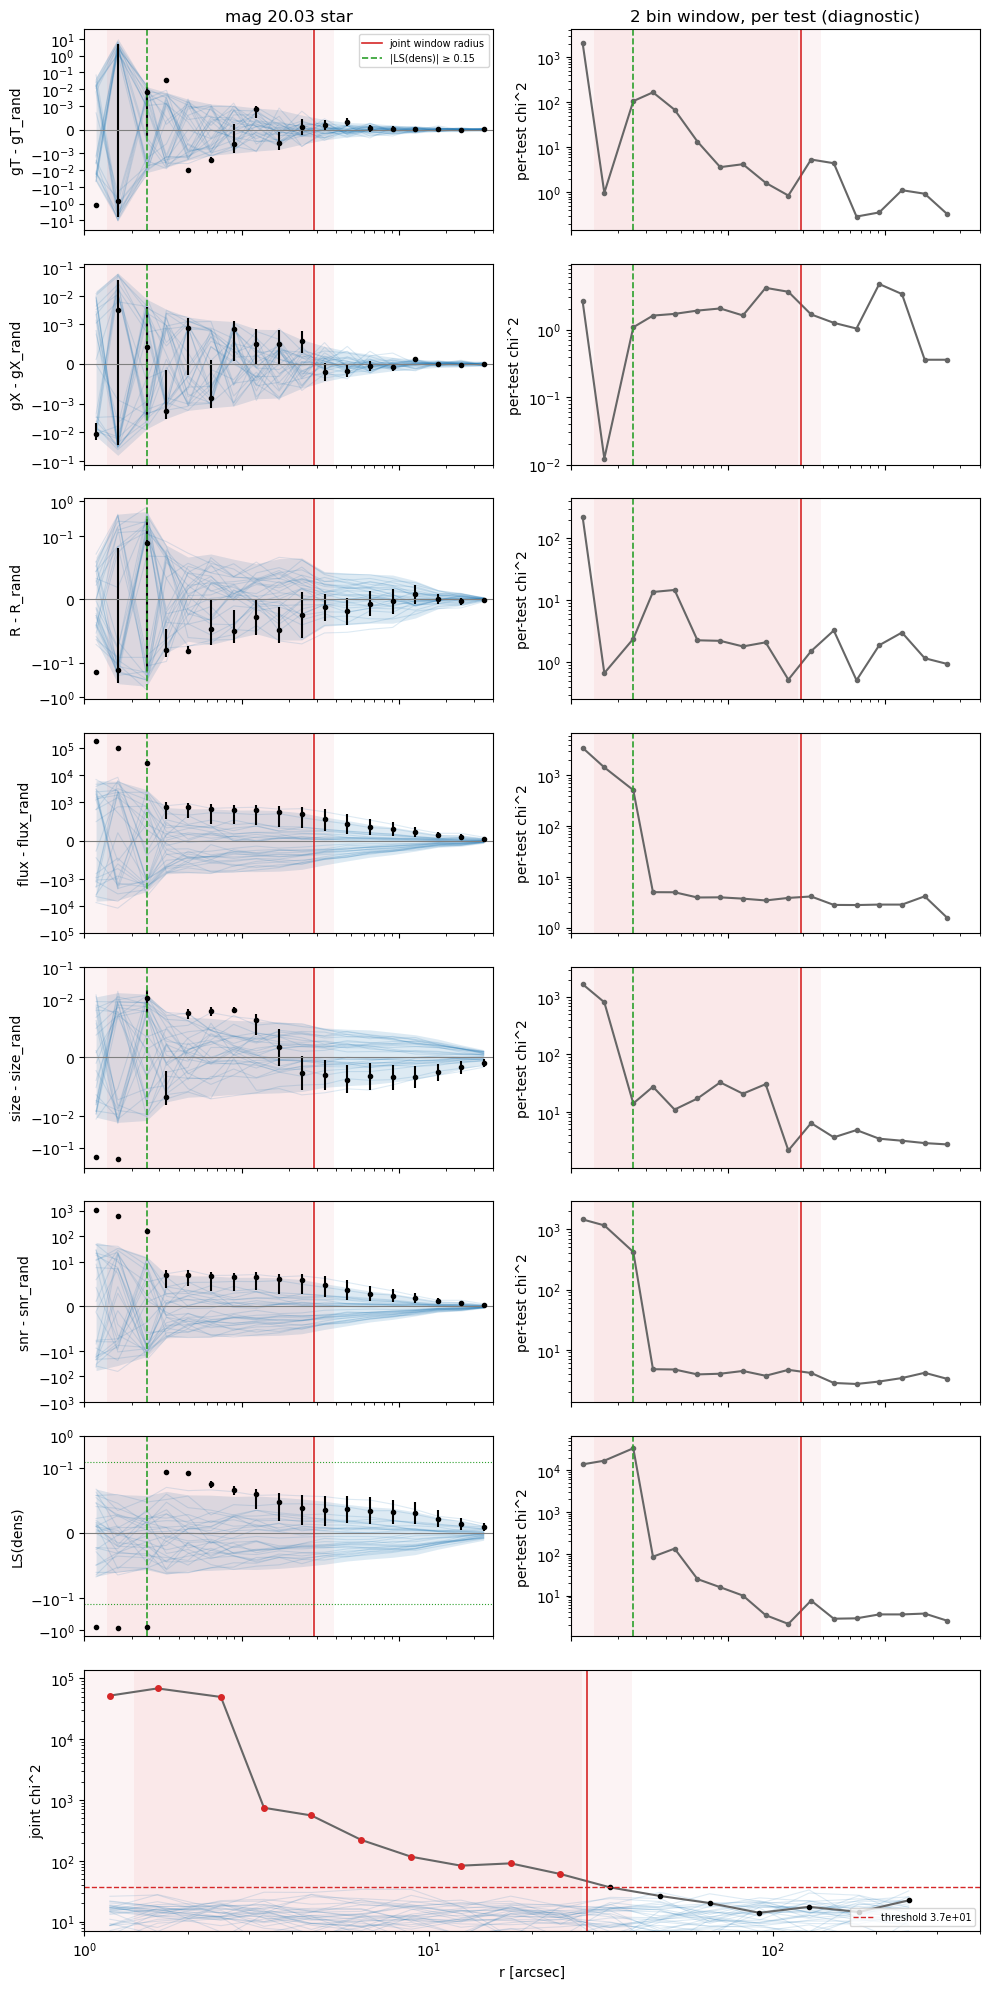

In [3]:
# ---- settings ---------------------------------------------------------------
WIDTH    = 2      # radial bins per window
ALPHA    = 0.01   # chance that pure noise fails anywhere in the scan
N_SIMS   = 5000    # noise simulations used to set the threshold
SHOW_SIMS = True   # draw the noise simulations in each figure
DENS_CUT = 0.15    # simple density cut: outermost bin with |xi_LS| >= DENS_CUT
RELATIVE = False
JOINT_TESTS = ["gT", "gX", "R", "flux", "size", "snr", 'dens']  # tests included in the joint chi^2 (any subset of NULL_TESTS)
# JOINT_TESTS = ["gT", "gX"] 

def load_null(star_file, rand_file):
    """star - random for every test, for the data and for every jackknife row."""
    S = np.load(star_file, allow_pickle=True)
    Q = np.load(rand_file, allow_pickle=True)
    nt, nb = len(QUANTITIES), int(S["nbins"])
    assert np.allclose(S["patch_centers"], Q["patch_centers"])

    dS, dQ = S["data"].reshape(nt, nb), Q["data"].reshape(nt, nb)
    AS, AQ = S["design"].reshape(-1, nt, nb), Q["design"].reshape(-1, nt, nb)

    ig, ir = QUANTITIES.index("nn"), QUANTITIES.index("nr")
    def ls(s, q):                       # works on (nm, nb) and (Np, nm, nb)
        DD, DR = s[..., ig, :], s[..., ir, :]
        RD, RR = q[..., ig, :], q[..., ir, :]
        return (DD - DR - RD + RR) / RR

    rows_d, rows_A = [], []
    for q in NULL_TESTS:
        if q == "dens":
            rows_d.append(ls(dS, dQ))
            rows_A.append(ls(AS, AQ))
        else:
            j = QUANTITIES.index(q)
            rows_d.append(dS[j] - dQ[j])
            rows_A.append(AS[:, j] - AQ[:, j])
    d = np.stack(rows_d)                # (ntest, nb)
    A = np.stack(rows_A, axis=1)        # (Np, ntest, nb)

    # drop inner bins that are empty in some jackknife row (RR = 0 -> NaN)
    bad = ~np.isfinite(d).all(0) | ~np.isfinite(A).all((0, 1))
    k0 = np.flatnonzero(bad).max() + 1 if bad.any() else 0
    return d[:, k0:], A[:, :, k0:], S["edges_as"][k0:], S["r_as"][k0:]

def window_chi(v, A, hartlap=True):
    """Per-test chi^2 vs zero for every test and window (shown for diagnosis;
    the decision uses joint_chi). v: (..., ntest, nb); A: (Np, ntest, nb)."""
    Np, nt, nb = A.shape
    nwin = nb - WIDTH + 1
    h = (Np - WIDTH - 2) / (Np - 1) if hartlap else 1.0
    chi = np.empty(v.shape[:-1] + (nwin,))
    for t in range(nt):
        for i in range(nwin):
            X = A[:, t, i:i + WIDTH]
            D = X - X.mean(0)
            Cinv = h * np.linalg.inv((Np - 1) / Np * D.T @ D)
            x = v[..., t, i:i + WIDTH]
            chi[..., t, i] = np.einsum("...a,ab,...b->...", x, Cinv, x)
    return chi

def joint_chi(v, A, hartlap=True):
    """Joint chi^2 vs zero for every window: all tests in JOINT_TESTS and all
    WIDTH bins together, with the full covariance between tests and bins.
    v: (..., ntest, nb); A: (Np, ntest, nb). Returns (..., nwin)."""
    sel = [NULL_TESTS.index(q) for q in JOINT_TESTS]
    Np, _, nb = A.shape
    nwin = nb - WIDTH + 1
    k = len(sel) * WIDTH                                       # numbers per window
    h = (Np - k - 2) / (Np - 1) if hartlap else 1.0            # Hartlap correction
    chi = np.empty(v.shape[:-2] + (nwin,))
    for i in range(nwin):
        X = A[:, sel, i:i + WIDTH].reshape(Np, k)              # all tests x bins in window
        D = X - X.mean(0)
        Cinv = h * np.linalg.inv((Np - 1) / Np * D.T @ D)      # k x k jackknife covariance
        x = v[..., sel, i:i + WIDTH].reshape(v.shape[:-2] + (k,))
        chi[..., i] = np.einsum("...a,ab,...b->...", x, Cinv, x)
    return chi

def window_test(star_file, rand_file, spot=0.5, seed=0):
    d, A, edges, r = load_null(star_file, rand_file)
    Np = len(A)
    sigma = np.sqrt((Np - 1) / Np * ((A - A.mean(0)) ** 2).sum(0))   # per-bin error

    # 1. joint chi2 of every window for the data (+ per-test chi2s for diagnosis)
    jchi = joint_chi(d, A)
    chi = window_chi(d, A)

    # 2. threshold: pure-noise data vectors with the full covariance, run through
    #    the same scan; take each sim's largest joint chi2 over windows
    D = A.reshape(Np, -1) - A.reshape(Np, -1).mean(0)
    z = np.random.default_rng(seed).standard_normal((N_SIMS, Np))
    sims = (np.sqrt((Np - 1) / Np) * z @ D).reshape(N_SIMS, *d.shape)
    jchi_sims = joint_chi(sims, A, hartlap=False)   # sims use the covariance they came from
    worst = jchi_sims.max(-1)
    thresh = np.quantile(worst, 1 - ALPHA)

    # 3. window labels: center data point (inner of the two middle bins for even WIDTH)
    # c = np.arange(jchi.size) + (WIDTH - 1) // 2
    c = np.arange(jchi.size) + int(spot)
    x_win = r[c]
    r_win = r[c] if spot == np.floor(spot) else 0.5 * (r[c] + r[c + 1])

    # 4. a window fails if its joint chi is above the threshold;
    #    the radius is that of the outermost failing window
    failing = np.flatnonzero(jchi > thresh)
    out = dict(d=d, sigma=sigma, r=r, edges=edges, chi=chi, jchi=jchi, thresh=thresh,
               x_win=x_win, r_win=r_win, failing=failing,
               sims=sims, jchi_sims=jchi_sims, worst_sims=worst, worst_data=jchi.max())

    big = np.flatnonzero(np.abs(d[NULL_TESTS.index("dens")]) >= DENS_CUT)
    out["dens_radius"] = r[big[-1]] if big.size else np.nan

    if failing.size:
        i = failing[-1]
        # tests driving the failure: largest per-test chis in that window (diagnostic only)
        order = np.argsort(chi[:, i])[::-1][:3]
        out.update(radius=r_win[i], win_lo=edges[i], win_hi=edges[i + WIDTH], no_fail=False,
                   tests=[f"{NULL_TESTS[t]} ({chi[t, i]:.1f})" for t in order])
    else:
        out.update(radius=r[0], win_lo=edges[0], win_hi=edges[1], no_fail=True, tests=[])
    return out

def symlog_axis(a, sigma):
    """y axis linear within ~1 sigma of zero, logarithmic beyond."""
    lt = np.median(sigma) * 2
    a.set_yscale("symlog", linthresh=lt)
    top = np.abs(a.get_ylim()).max()
    dec = 10.0 ** np.arange(np.ceil(np.log10(lt)), np.floor(np.log10(top)) + 1)
    a.set_yticks(np.concatenate([-dec[::-1], [0], dec]))
    a.minorticks_off()

def plot_bin(res, title="", show_sims=None, n_show=30):
    """One figure per star bin.
    Left:  each null test, star - random +/- sigma (sims in blue).
    Right: per-test window chis (grey, diagnostic only).
    Bottom row: the joint chi that decides; red points above the threshold."""
    if show_sims is None:
        show_sims = SHOW_SIMS
    nt = len(NULL_TESTS)
    r, edges, xw = res["r"], res["edges"], res["x_win"]
    floor = 1e-12
    fig = plt.figure(figsize=(10, 2.5 * nt + 2.5))
    gs = fig.add_gridspec(nt + 1, 2, height_ratios=[1] * nt + [1.3])
    ax = np.array([[fig.add_subplot(gs[t, 0]), fig.add_subplot(gs[t, 1])] for t in range(nt)])
    axj = fig.add_subplot(gs[nt, :])

    for t, q in enumerate(NULL_TESTS):
        a, b = ax[t]
        s = res["sigma"][t]
        if show_sims:
            sims_t = res["sims"][:, t]
            lo, hi = np.percentile(sims_t, [2.5, 97.5], axis=0)
            scale = s if RELATIVE else 1.0
            a.plot(r, (sims_t[:n_show] / scale).T, color="C0", alpha=0.15, lw=0.8)
            a.fill_between(r, lo / scale, hi / scale, color="C0", alpha=0.15, lw=0)
        if RELATIVE:
            a.errorbar(r, res["d"][t] / s, yerr=1, fmt="o", ms=3, color="k")
            a.set_ylim(-4, 4)
            a.set_ylabel(f"LS({q}) / sigma" if q == "dens" else f"({q} - {q}_rand) / sigma")
        else:
            a.errorbar(r, res["d"][t], yerr=s, fmt="o", ms=3, color="k")
            symlog_axis(a, s)
            a.set_ylabel(f"LS({q})" if q == "dens" else f"{q} - {q}_rand")
        a.axhline(0, color="0.5", lw=0.8)

        b.semilogy(xw, np.maximum(res["chi"][t], floor), "-o", ms=3, color="0.4")
        b.set_ylim(max(res["chi"][t].min() / 2, 1e-2), res["chi"][t].max() * 2)
        b.set_ylabel("per-test chi^2")

        for x in (a, b):
            for i in res["failing"]:
                x.axvspan(edges[i], edges[i + WIDTH], color="C3", alpha=0.05, lw=0)
            x.axvline(res["radius"], color="C3", lw=1.2, ls=":" if res["no_fail"] else "-")
            if np.isfinite(res["dens_radius"]):
                x.axvline(res["dens_radius"], color="C2", lw=1.2, ls="--")
            x.set_xscale("log")
            x.set_xlim(edges[0], edges[-1])
            x.tick_params(labelbottom=False)

    # joint chi: the statistic that decides
    if show_sims:
        axj.semilogy(xw, np.maximum(res["jchi_sims"][:n_show], floor).T, color="C0", alpha=0.15, lw=0.8)
    jp = np.maximum(res["jchi"], floor)
    fail = jp > res["thresh"]
    axj.semilogy(xw, jp, "-", color="0.4")
    axj.semilogy(xw[~fail], jp[~fail], "o", ms=3, color="k")
    axj.semilogy(xw[fail], jp[fail], "o", ms=4, color="C3")
    axj.axhline(res["thresh"], color="C3", ls="--", lw=1, label=f"threshold {res['thresh']:.1e}")
    for i in res["failing"]:
        axj.axvspan(edges[i], edges[i + WIDTH], color="C3", alpha=0.05, lw=0)
    axj.axvline(res["radius"], color="C3", lw=1.2, ls=":" if res["no_fail"] else "-")
    axj.set_xscale("log")
    axj.set_xlim(edges[0], edges[-1])
    axj.set_ylim(max(res["jchi"].min() / 2, 1e-2), max(res["thresh"], res["jchi"].max()) * 2)
    axj.set_ylabel("joint chi^2")
    axj.set_xlabel("r [arcsec]")
    axj.legend(fontsize=7, loc="lower right")

    ax[0, 0].set_title(f"{title} star")
    ax[0, 1].set_title(f"{WIDTH} bin window, per test (diagnostic)")
    t_d = NULL_TESTS.index("dens")
    if not RELATIVE:
        for sgn in (-1, 1):
            ax[t_d, 0].axhline(sgn * DENS_CUT, color="C2", lw=0.8, ls=":")
    ax[0, 0].plot([], [], color="C3", lw=1.2, label="joint window radius")
    ax[0, 0].plot([], [], color="C2", lw=1.2, ls="--", label=f"|LS(dens)| ≥ {DENS_CUT}")
    ax[0, 0].legend(fontsize=7, loc="upper right")
    fig.tight_layout()
    plt.show()

results = []
for b, c, mag, _ in mag_cuts:
    star_file = f"{save_path}/star_mag{mag}.npz"
    rand_file = f"{save_path}/rands_b{b}_w{c}.npz"
    res = window_test(star_file, rand_file)
    mean_mag = np.load(star_file, allow_pickle=True)["config"].item()["mean_mag"]
    results.append((mean_mag, res["win_lo"], res["win_hi"], res["radius"], res["dens_radius"]))
    tag = ("no failure, smallest bin" if res["no_fail"]
           else f"strongest tests: {', '.join(res['tests'])}")
    print(f"mag {mean_mag:.2f}, window radius {res['radius']:.1f} arcsec "
          f"({res['radius'] / 0.2:.0f} pix), {tag}, "
          f"dens_cut: {res['dens_radius']:.1f} arcsec ({res['dens_radius'] / 0.2:.0f} pix)")
    plot_bin(res, title=f"mag {mean_mag:.2f}")

results = np.array(results)

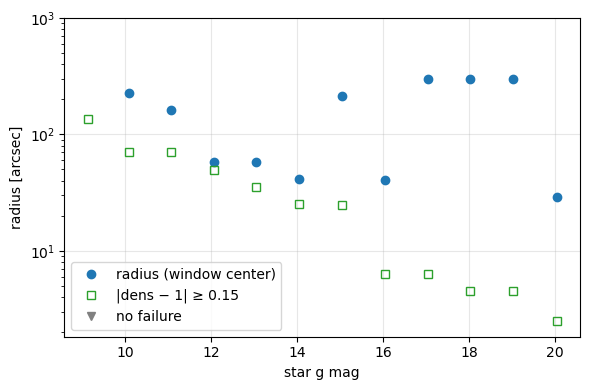

In [4]:
m, w_lo, w_hi, rad, rad_dens = results.T
ok = np.isfinite(rad)
## do fits:

fig, ax = plt.subplots(figsize=(6, 4))
# ax.vlines(m[ok], w_lo[ok], w_hi[ok], color="C0", lw=2, alpha=0.4, label="failing window")
ax.plot(m[ok], rad[ok], "o", color="C0", label="radius (window center)")
ax.plot(m, rad_dens, "s", mfc="none", color="C2", label=f"|dens − 1| ≥ {DENS_CUT}")
ax.plot(m[~ok], np.full((~ok).sum(), np.nanmin(w_lo) if ok.any() else 1), "v",
        color="0.5", label="no failure")
ax.set_yscale("log")
ax.set_xlabel("star g mag")
ax.set_ylabel("radius [arcsec]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(None,1000)
fig.tight_layout()
plt.show()

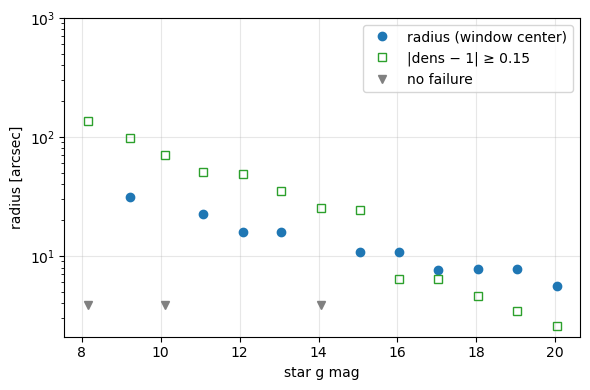

In [8]:
m, w_lo, w_hi, rad, rad_dens = results.T
ok = np.isfinite(rad)
## do fits:

fig, ax = plt.subplots(figsize=(6, 4))
# ax.vlines(m[ok], w_lo[ok], w_hi[ok], color="C0", lw=2, alpha=0.4, label="failing window")
ax.plot(m[ok], rad[ok], "o", color="C0", label="radius (window center)")
ax.plot(m, rad_dens, "s", mfc="none", color="C2", label=f"|dens − 1| ≥ {DENS_CUT}")
ax.plot(m[~ok], np.full((~ok).sum(), np.nanmin(w_lo) if ok.any() else 1), "v",
        color="0.5", label="no failure")
ax.set_yscale("log")
ax.set_xlabel("star g mag")
ax.set_ylabel("radius [arcsec]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(None,1000)
fig.tight_layout()
plt.show()

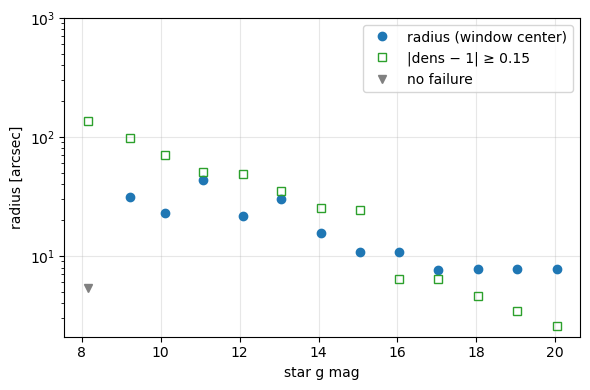

In [ ]:
m, w_lo, w_hi, rad, rad_dens = results.T
ok = np.isfinite(rad)
## do fits:

fig, ax = plt.subplots(figsize=(6, 4))
# ax.vlines(m[ok], w_lo[ok], w_hi[ok], color="C0", lw=2, alpha=0.4, label="failing window")
ax.plot(m[ok], rad[ok], "o", color="C0", label="radius (window center)")
ax.plot(m, rad_dens, "s", mfc="none", color="C2", label=f"|dens − 1| ≥ {DENS_CUT}")
ax.plot(m[~ok], np.full((~ok).sum(), np.nanmin(w_lo) if ok.any() else 1), "v",
        color="0.5", label="no failure")
ax.set_yscale("log")
ax.set_xlabel("star g mag")
ax.set_ylabel("radius [arcsec]")
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(None,1000)
fig.tight_layout()
plt.show()

In [ ]:
# ---- settings ---------------------------------------------------------------
WIDTH    = 3     # radial bins per window
MIN_FAIL = 2       # number of tests that must fail in the same window
ALPHA    = 0.05    # chance that pure noise fails anywhere in the scan
N_SIMS   = 2000    # noise simulations used to set the threshold
SHOW_SIMS = True   # draw the noise simulations and the threshold histogram in each figure
DENS_CUT = 0.15    # simple density cut: outermost bin with |dens/dens_rand - 1| >= DENS_CUT
RELATIVE = False

def basic_plot(star_file, rand_file, title):
    S = np.load(star_file, allow_pickle=True)
    Q = np.load(rand_file, allow_pickle=True)
    nt, nb = len(QUANTITIES), int(S["nbins"])

    dS, dQ = S["data"].reshape(nt, nb), Q["data"].reshape(nt, nb)
    AS, AQ = S["design"].reshape(-1, nt, nb), Q["design"].reshape(-1, nt, nb)

    bad = ~np.isfinite(dS).all(0) | ~np.isfinite(AS).all((0, 1))
    k0 = np.flatnonzero(bad).max() + 1 if bad.any() else 0
    d, A, edges, r = dS[:, k0:], AS[:, :, k0:], S["edges_as"][k0:], S["r_as"][k0:]

    dq, Q, qedges, qr = dQ[:, k0:], AQ[:, :, k0:], Q["edges_as"][k0:], Q["r_as"][k0:]

    Np = len(A)
    sigma = np.sqrt((Np - 1) / Np * ((A - A.mean(0)) ** 2).sum(0))
    qNp = len(Q)
    qsigma = np.sqrt((qNp - 1) / qNp * ((Q - Q.mean(0)) ** 2).sum(0))

    fig, ax = plt.subplots(nt, figsize=(6, 3 * nt ))
    for t, q in enumerate(QUANTITIES):
        a = ax[t]

        if RELATIVE:
            a.errorbar(r, d[t]/sigma[t], yerr=1, fmt="o", ms=3)
            a.errorbar(qr, dq[t]/qsigma[t], yerr=1, fmt="o", ms=3)
            # a.set_ylim(-4,4)
            # symlog_axis(a, res["sigma"][t])
            a.set_ylabel(f"{q} / sigma" if (q == "gT" or q == 'gX') else f"({q}/{q}_rand - 1) / sigma")
        else:
            a.errorbar(r, d[t], yerr=sigma[t], fmt="o", ms=3)
            a.errorbar(qr, dq[t], yerr=qsigma[t], fmt="o", ms=3)
            # a.errorbar(qr, d[t]/dq[t]-1, yerr=np.abs(sigma[t]/dq[t]), fmt="o", ms=3)
            # symlog_axis(a, sigma[t])
            a.set_ylabel(f"{q}" if (q == "gT" or q == 'gX') else f"{q}/{q}_rand - 1")
        # a.axhline(0, color="0.5", lw=0.8)

        a.set_xscale("log")
        a.set_xlim(edges[0], edges[-1])
        if t < nt - 1:
            a.tick_params(labelbottom=False)
    ax[-1].set_xlabel("r [arcsec]")
    ax[0].set_title(f"{title} mag star")
    fig.tight_layout()
    plt.show()


for ind, mag, _ in mag_cuts:
    star_file = f"{save_path}/star_mag{mag}.npz"
    rand_file = f"{save_path}/rand_{ind}.npz"
    basic_plot(star_file, rand_file, mag)
